# Partage de Threat Intelligence préservant la confidentialité par cryptographie avancée
**Privacy-Preserving Threat-Intelligence Sharing : chiffrement homomorphe, post-quantique, preuves à divulgation nulle (ZKP) et interopérabilité STIX 2.1**

*Cryptographie avancée et ingénierie de la vie privée — ICCN INE3, INPT — Pr. Ch. HANIN — 2026-2027*

## Problème
Plusieurs SOC/CSIRT (banque, télécom, hôpital, administration) détiennent chacun des **indicateurs de compromission (IOC)** privés : adresses IP, domaines, empreintes de fichiers, URL.
Ils veulent identifier **les IOC qu'ils ont en commun** (= une campagne frappe plusieurs secteurs) **sans révéler le reste de leurs listes**, car
une liste d'IOC révèle ce dont l'organisation a été victime, ce qu'elle surveille et parfois qui sont ses clients.

## Ce que ce notebook implémente (entièrement from scratch, Python pur + NumPy)
| # | Composant | Chapitre du cours |
|---|-----------|----------------|
| 1 | Normalisation des IOC et **flux publics réels de threat intelligence** (chaque flux joue le rôle d'une organisation) | – |
| 2 | **Baseline** : partage naïf de hachés + attaque par dictionnaire (pourquoi la cryptographie avancée est nécessaire) | Ch. 0 (fonctions de hachage, hypothèses) |
| 3 | **PSI polynomial de Paillier** (chiffrement additivement homomorphe) + binning | Ch. 2 (HE) |
| 4 | **PSI LWE / filtre de Bloom** (post-quantique, à base de réseaux euclidiens, paramètres jouets) | Ch. 1 (LWE) + Ch. 2 |
| 5 | **Preuve à divulgation nulle** (Chaum–Pedersen DLEQ batché) sur une transcription DH-PSI minimale, dans un groupe de nombre premier sûr | Ch. 0 (DDH/CDH) + Ch. 4 (ZK) |
| 6 | **Export STIX 2.1** des intersections trouvées par Paillier et LWE (interopérabilité SIEM/TIP) | – |
| 7 | Synthèse des vérifications, coûts mesurés et enseignements | – |
| 8 | **Visualisations** : attaque par dictionnaire, binning Paillier, fuite LWE/Bloom, preuve DLEQ batchée, synthèse des coûts | – |

## Pipeline de données et de protocoles
```text
flux publics réels ──normalize_ioc──▶ orgs {org: {ioc: métadonnées}} ──▶ paire réelle (X, Y)
                                                                          ├─▶ Paillier-PSI (HE)    ──┐
                                                                          ├─▶ LWE-Bloom-PSI (PQ)   ──┼─▶ bundle STIX 2.1 ─▶ SIEM / TIP
                                                                          └─▶ transcription DH ─▶ preuve DLEQ (honnêteté du serveur)
```

## Modèle de menace
* Participants **semi-honnêtes (honest-but-curious)** pour Paillier-PSI et LWE-PSI : ils suivent le protocole mais analysent la transcription.
* Canal sécurisé (TLS) supposé ; on étudie la fuite *cryptographique* au-dessus de celui-ci.
* Fonctionnalité idéale : $\mathcal{F}_{PSI}((X, Y)) = (X\cap Y,\ |X|\text{ et }|Y|\text{ divulgués})$. Chaque protocole est comparé à cet idéal.
* La section 4 traite un adversaire **quantique** (LWE au lieu de la factorisation ou du log discret) ; la section 5 traite un serveur **malveillant** (preuve ZK de cohérence de clé).

> Les paramètres sont choisis pour que tout s'exécute en quelques minutes sur un portable. Lorsqu'un paramètre est *jouet* (LWE, taille du module de Paillier), la cellule le précise.

In [1]:
# --- Initialisation ------------------------------------------------------
import importlib, subprocess, sys

def _ensure(pkg, imp=None):
    try:
        importlib.import_module(imp or pkg)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

for _pkg in ("numpy", "pandas", "mpmath"):
    _ensure(_pkg)

import hashlib, secrets, time, random, math, re, json, ipaddress, uuid, datetime, os
import urllib.request, urllib.parse
from collections import Counter
from dataclasses import dataclass
import numpy as np
import pandas as pd
from mpmath import mp

FAST = True          # False => ensembles plus grands (plusieurs minutes de plus)
SEED = 1337          # uniquement pour l'échantillonnage reproductible des flux réels ; toute l'aléa cryptographique utilise `secrets`
_sysrand = secrets.SystemRandom()

CHECKS = []
def check(name, cond):
    """Enregistre + vérifie (assert) un contrôle de correction (récapitulé à la fin)."""
    CHECKS.append((name, bool(cond)))
    assert cond, f"VÉRIFICATION ÉCHOUÉE : {name}"
    print(f"[ok] {name}")

print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.4.4 | pandas 3.0.2


## 0b. Configuration des graphiques

Les cellules « Graphe » ajoutées dans ce notebook utilisent **matplotlib**. Chaque figure est aussi enregistrée en PNG dans le dossier `figures/` (pratique pour le rapport).
Toutes les valeurs tracées sont **mesurées pendant l'exécution** (aucun chiffre n'est saisi à la main).

In [2]:
_ensure("matplotlib")
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, NullLocator

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "figure.facecolor": "white",
    "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelsize": 10, "legend.frameon": False,
})
C = {"bleu": "#2b6cb0", "vert": "#2f9e44", "rouge": "#d9480f", "violet": "#7048e8", "gris": "#868e96", "or": "#e6a700"}
FIG_DIR = "figures"; os.makedirs(FIG_DIR, exist_ok=True)

def save_fig(fig, name):
    fig.tight_layout()
    fig.savefig(os.path.join(FIG_DIR, name + ".png"), bbox_inches="tight")
    plt.show()

def fmt_t(s: float) -> str:
    """Durée lisible (ms, s, min, h, jours)."""
    if s < 1e-6: return f"{s * 1e9:.0f} ns"
    if s < 1e-3: return f"{s * 1e6:.0f} µs"
    if s < 1:    return f"{s * 1e3:.0f} ms"
    if s < 60:   return f"{s:.1f} s"
    if s < 3600: return f"{s / 60:.1f} min"
    if s < 86400: return f"{s / 3600:.1f} h"
    return f"{s / 86400:.0f} j"

print("matplotlib", matplotlib.__version__, "| figures enregistrées dans", FIG_DIR + "/")

matplotlib 3.10.8 | figures enregistrées dans figures/


## 1. Normalisation des IOC et flux publics réels de threat intelligence

Le PSI est un protocole de correspondance *exacte* : **la normalisation fait donc partie de la conception de sécurité**. `Evil[.]COM.` et `evil.com` doivent donner la même chaîne,
sinon l'intersection rate silencieusement une correspondance. On préfixe aussi chaque IOC par son type afin qu'une chaîne d'IP ne puisse jamais entrer en collision avec un domaine.

In [3]:
_SHA256_RE = re.compile(r"^[0-9a-fA-F]{64}$")
_DOMAIN_RE = re.compile(r"^(?=.{1,253}$)([a-z0-9_]([a-z0-9_-]{0,61}[a-z0-9_])?\.)+[a-z]{2,63}$")

def refang(s: str) -> str:
    s = s.strip()
    for a, b in (("[.]", "."), ("(.)", "."), ("[dot]", "."), ("[:]", ":"), ("[://]", "://")):
        s = s.replace(a, b)
    return re.sub(r"^hxxp", "http", s, flags=re.I)

def normalize_ioc(raw: str, kind: str = None) -> str:
    """Retourne une chaîne d'IOC canonique préfixée par son type, p. ex. 'ip:1.2.3.4'."""
    s = refang(raw)
    if kind is None:
        if _SHA256_RE.match(s):
            kind = "sha256"
        elif "://" in s:
            kind = "url"
        else:
            try:
                ipaddress.ip_address(s); kind = "ip"
            except ValueError:
                kind = "domain"
    if kind == "sha256":
        if not _SHA256_RE.match(s): raise ValueError(f"sha256 invalide : {raw}")
        return "sha256:" + s.lower()
    if kind == "ip":
        return "ip:" + str(ipaddress.ip_address(s))
    if kind == "domain":
        d = s.lower().rstrip(".")
        if not _DOMAIN_RE.match(d): raise ValueError(f"domaine invalide : {raw}")
        return "domain:" + d
    if kind == "url":
        m = re.match(r"^([a-zA-Z][a-zA-Z0-9+.-]*)://([^/\s:?#]+)(:\d+)?(.*)$", s)
        if not m: raise ValueError(f"url invalide : {raw}")
        scheme, host, port, rest = m.groups()
        return f"url:{scheme.lower()}://{host.lower().rstrip('.')}{port or ''}{rest}"
    raise ValueError(f"type inconnu : {kind}")

assert normalize_ioc("hxxp://Evil[.]Example[.]com/Path") == "url:http://evil.example.com/Path"
assert normalize_ioc("8.8.8[.]8") == "ip:8.8.8.8"
assert normalize_ioc("Evil.COM.") == "domain:evil.com"
assert normalize_ioc("A" * 64) == "sha256:" + "a" * 64
print("tests de normalisation réussis")

tests de normalisation réussis


### 1b. IOC réels issus de flux publics de threat intelligence

On charge des **IOC réels et actuels** depuis des flux publics. Chaque flux joue le rôle de **la liste privée d'une organisation**
(par défaut : IPsum, CINS Army, Blocklist.de, Emerging Threats, domaines et URL de Phishing Database ; en `OPTIONAL_FEEDS` : abuse.ch Feodo/URLhaus/MalwareBazaar, OpenPhish, listes C2/hash de Neo23x0).
Leur recouvrement est le *vrai* recouvrement entre sources indépendantes, et non un recouvrement planté. Les flux de hachés recoupent rarement les IOC réseau, ce qui est réaliste : le PSI renvoie simplement une intersection vide dans ce cas.

* **Cadrage honnête pour le rapport :** ces flux étant publics, la « confidentialité » est ici simulée. Dans un déploiement réel, chaque partie alimente le **même code** avec sa télémétrie *privée* (hits SIEM/EDR/pare-feu). Rien ne change dans les protocoles.
* **Échantillonnage coordonné :** pour garder des temps d'exécution raisonnables, on plafonne chaque organisation à `MAX_PER_ORG` IOC. Les IOC détenus par ≥ 2 flux sont conservés dans un ordre *cohérent* (par haché) pour toutes les organisations, de sorte que les vrais recouvrements survivent au plafonnement ; le reste est complété par des IOC aléatoires propres à un seul flux.
* **Reproductibilité :** chaque flux téléchargé est mis en cache dans `feed_cache/` (les flux changent chaque jour). Supprimer le dossier pour rafraîchir. On peut aussi ajouter sa propre liste avec `LOCAL_FILES = {"Mon-SOC": "mes_iocs.txt"}` (un IOC par ligne).
* **Sécurité :** le notebook ne manipule les IOC que comme des *chaînes de caractères*. Ne jamais ouvrir les URL ni exécuter les hachés. Vérifier les conditions d'utilisation de chaque flux avant réutilisation (la plupart des flux abuse.ch sont CC0 ; certains sont réservés à un usage non commercial).
* **Pas de repli synthétique :** tous les protocoles ci-dessous s'exécutent exclusivement sur des IOC issus de ces flux. Si moins de 3 flux sont accessibles (pas d'internet), le notebook s'arrête avec une erreur explicite ; pré-remplir `feed_cache/` ou `LOCAL_FILES` pour travailler hors ligne.

In [4]:
MAX_PER_ORG = 300 if FAST else 1000
PAIR = None                          # impose les deux organisations des protocoles à 2 parties, p. ex. ("IPsum", "Blocklist.de") ; None = plus grand recouvrement réel
CACHE_DIR = "feed_cache"
IPSUM_MIN_LISTS = 3                  # IPsum : garder les IP signalées par >= 3 listes de blocage indépendantes
_GH = "https://raw.githubusercontent.com"
FEEDS = [  # (nom de l'organisation, URL, mode d'analyse)   -- tous hébergés sur GitHub, donc accessibles depuis Colab / la plupart des réseaux
    ("IPsum",           f"{_GH}/stamparm/ipsum/master/ipsum.txt",                                   "ipsum"),  # IP présentes sur >= 3 listes de blocage
    ("CI-Army",         f"{_GH}/firehol/blocklist-ipsets/master/ciarmy.ipset",                       "ip"),     # liste CINS Army
    ("Blocklist.de",    f"{_GH}/firehol/blocklist-ipsets/master/blocklist_de.ipset",                 "ip"),     # attaques signalées par honeypots / fail2ban
    ("ET-Compromised",  f"{_GH}/firehol/blocklist-ipsets/master/et_compromised.ipset",               "ip"),     # hôtes compromis Emerging Threats
    ("Phishing-domains", f"{_GH}/mitchellkrogza/Phishing.Database/master/phishing-domains-ACTIVE.txt", "auto"),   # domaines de phishing actifs
    ("Phishing-links",  f"{_GH}/mitchellkrogza/Phishing.Database/master/phishing-links-ACTIVE.txt",  "url"),    # URL de phishing actives (+ leurs hôtes)
]
OPTIONAL_FEEDS = [  # sources supplémentaires : ajouter avec `FEEDS += OPTIONAL_FEEDS` (certaines peuvent être bloquées sur réseaux restreints -> elles sont ignorées)
    ("GreenSnow",       f"{_GH}/firehol/blocklist-ipsets/master/greensnow.ipset",                    "ip"),
    ("BruteForceBlocker", f"{_GH}/firehol/blocklist-ipsets/master/bruteforceblocker.ipset",          "ip"),
    ("Phishing-IPs",    f"{_GH}/mitchellkrogza/Phishing.Database/master/phishing-IPs-ACTIVE.txt",    "ip"),
    ("Neo23x0-C2",      f"{_GH}/Neo23x0/signature-base/master/iocs/c2-iocs.txt",                     "auto"),
    ("Neo23x0-hashes",  f"{_GH}/Neo23x0/signature-base/master/iocs/hash-iocs.txt",                   "sha256"),
    ("Feodo-Tracker",   "https://feodotracker.abuse.ch/downloads/ipblocklist.txt",                   "ip"),
    ("URLhaus",         "https://urlhaus.abuse.ch/downloads/text_online/",                           "url"),
    ("OpenPhish",       "https://openphish.com/feed.txt",                                            "url"),
    ("MalwareBazaar",   "https://bazaar.abuse.ch/export/txt/sha256/recent/",                         "sha256"),
]
LOCAL_FILES = {}                     # p. ex. {"Mon-SOC": "mes_iocs.txt"}  (détecte automatiquement IP / domaines / URL / hachés)

_TOKEN_SPLIT = re.compile(r"[\s,;\"']+")

def _safe_norm(tok, kind=None):
    try:
        return normalize_ioc(tok, kind)
    except Exception:
        return None

def _stable(x: str) -> str:
    """Clé d'ordre déterministe, indépendante de l'organisation (sert à l'échantillonnage coordonné)."""
    return hashlib.sha256(x.encode()).hexdigest()

def parse_feed(text: str, mode: str) -> dict:
    """Analyse un flux en {IOC normalisé : confiance}. Les lignes commençant par '#' sont des commentaires."""
    out = {}
    for line in text.splitlines():
        line = line.strip()
        if not line or line.startswith("#") or line.startswith("//"):
            continue
        toks = [t for t in _TOKEN_SPLIT.split(line) if t]
        if not toks:
            continue
        if mode == "ipsum":                                   # "<ip>\t<nombre de listes de blocage>"
            ioc = _safe_norm(toks[0], "ip")
            if ioc and len(toks) > 1 and toks[1].isdigit() and int(toks[1]) >= IPSUM_MIN_LISTS:
                out[ioc] = min(95, 40 + 10 * int(toks[1]))
        elif mode == "ip":
            ioc = _safe_norm(toks[0], "ip")
            if ioc: out[ioc] = 80
        elif mode == "sha256":
            ioc = _safe_norm(toks[0], "sha256")
            if ioc: out[ioc] = 85
        elif mode == "url":                                   # garde l'URL et son hôte (ip: ou domain:)
            u = None if "@" in toks[0] else _safe_norm(toks[0], "url")      # ignore les URL contenant des identifiants
            if u:
                out[u] = 70
                host = urllib.parse.urlsplit(refang(toks[0])).hostname
                h = _safe_norm(host) if host else None
                if h: out[h] = 70
        else:                                                 # "auto"
            for t in toks:
                ioc = _safe_norm(t)
                if ioc: out[ioc] = 60
    return out

def fetch_feed(name: str, url: str):
    os.makedirs(CACHE_DIR, exist_ok=True)
    path = os.path.join(CACHE_DIR, re.sub(r"[^A-Za-z0-9_.-]", "_", name) + ".txt")
    if os.path.exists(path):
        return open(path, encoding="utf-8", errors="replace").read(), "cache"
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (INPT course project; PSI threat-intel demo)"})
    with urllib.request.urlopen(req, timeout=30) as r:
        text = r.read(30_000_000).decode("utf-8", errors="replace")
    with open(path, "w", encoding="utf-8") as f:
        f.write(text)
    return text, "téléchargement"

def load_real_feeds():
    full, status = {}, []
    for name, url, mode in FEEDS:
        try:
            text, src = fetch_feed(name, url)
            iocs = parse_feed(text, mode)
            if len(iocs) < 20: raise ValueError(f"seulement {len(iocs)} IOC analysés")
            full[name] = iocs; status.append((name, src, len(iocs), "ok"))
        except Exception as e:
            status.append((name, "-", 0, f"ignoré ({type(e).__name__}: {str(e)[:50]})"))
    for name, path in LOCAL_FILES.items():
        iocs = parse_feed(open(path, encoding="utf-8", errors="replace").read(), "auto")
        full[name] = iocs; status.append((name, "fichier local", len(iocs), "ok"))
    return full, pd.DataFrame(status, columns=["organisation", "source", "IOC analysés", "statut"])

def cap_sets(full: dict, cap: int) -> dict:
    """Échantillonnage coordonné : les IOC partagés sont gardés dans le même ordre (par haché) par toutes les orgs -> les recouvrements survivent au plafond."""
    counts = Counter(x for s in full.values() for x in s)
    rng = random.Random(SEED)
    out = {}
    for o, s in full.items():
        shared = sorted((x for x in s if counts[x] >= 2), key=_stable)
        priv = sorted(x for x in s if counts[x] == 1); rng.shuffle(priv)
        keep = shared[: cap // 2]
        keep += priv[: cap - len(keep)]
        out[o] = keep
    return out

def build_orgs_from_feeds(full: dict, cap: int) -> dict:
    snapshot = datetime.date.today().isoformat()
    return {o: {x: {"tag": o, "confidence": full[o][x], "first_seen": snapshot} for x in xs}
            for o, xs in cap_sets(full, cap).items()}

full_feeds, feed_status = load_real_feeds()
print(feed_status.to_string(index=False))
if len(full_feeds) < 3:
    raise RuntimeError("Moins de 3 flux réels ont pu être chargés (pas d'internet ?). Voir le tableau de statut ci-dessus ; "
                       "pré-remplir feed_cache/ ou renseigner LOCAL_FILES pour travailler hors ligne.")
orgs = build_orgs_from_feeds(full_feeds, MAX_PER_ORG)
REAL_UNIVERSE = set().union(*(set(v) for v in full_feeds.values()))     # tout IOC qui provient réellement d'un flux

# les deux organisations des démos à 2 parties passent en premier : `PAIR` si fourni, sinon la paire au plus grand recouvrement
_ol = list(orgs)
_pairs = sorted(((len(set(orgs[a]) & set(orgs[b])), a, b) for i, a in enumerate(_ol) for b in _ol[i + 1:]), reverse=True)
_first = list(PAIR) if PAIR else [_pairs[0][1], _pairs[0][2]]
assert all(o in orgs for o in _first), f"PAIR doit désigner deux flux chargés parmi {_ol}"
orgs = {o: orgs[o] for o in _first + [o for o in orgs if o not in _first]}
names = list(orgs)

print(f"\nSOURCE DES DONNÉES : flux publics de threat intelligence RÉELS (instantané du {datetime.date.today().isoformat()})")
kinds_tbl = pd.DataFrame({o: Counter(x.split(":", 1)[0] for x in v) for o, v in orgs.items()}).fillna(0).astype(int).T
kinds_tbl.insert(0, "total", [len(v) for v in orgs.values()])
print(kinds_tbl.to_string())
print("\nrecouvrements deux à deux (ce que le PSI devra retrouver) :")
for i, a in enumerate(names):
    for b in names[i + 1:]:
        print(f"  |{a} ∩ {b}| = {len(set(orgs[a]) & set(orgs[b]))}")
check("tous les IOC de chaque organisation proviennent d'un flux réel", all(set(v) <= REAL_UNIVERSE for v in orgs.values()))

    organisation         source  IOC analysés statut
           IPsum téléchargement         19879     ok
         CI-Army téléchargement         15000     ok
    Blocklist.de téléchargement         30544     ok
  ET-Compromised téléchargement           515     ok
Phishing-domains téléchargement        392149     ok
  Phishing-links téléchargement        478459     ok



SOURCE DES DONNÉES : flux publics de threat intelligence RÉELS (instantané du 2026-10-28)
                  total  domain  url   ip
Phishing-domains    300     296    1    3
Phishing-links      300     188  111    1
IPsum               300       0    0  300
CI-Army             300       0    0  300
Blocklist.de        300       0    0  300
ET-Compromised      300       0    0  300

recouvrements deux à deux (ce que le PSI devra retrouver) :
  |Phishing-domains ∩ Phishing-links| = 150
  |Phishing-domains ∩ IPsum| = 0
  |Phishing-domains ∩ CI-Army| = 0
  |Phishing-domains ∩ Blocklist.de| = 0
  |Phishing-domains ∩ ET-Compromised| = 0
  |Phishing-links ∩ IPsum| = 0
  |Phishing-links ∩ CI-Army| = 0
  |Phishing-links ∩ Blocklist.de| = 0
  |Phishing-links ∩ ET-Compromised| = 0
  |IPsum ∩ CI-Army| = 73
  |IPsum ∩ Blocklist.de| = 76
  |IPsum ∩ ET-Compromised| = 5
  |CI-Army ∩ Blocklist.de| = 4
  |CI-Army ∩ ET-Compromised| = 0
  |Blocklist.de ∩ ET-Compromised| = 3
[ok] tous les IOC de chaque or

### 1c. La paire réelle d'organisations utilisée par les protocoles

Paillier-PSI et LWE-PSI utilisent des paramètres jouets : ils s'exécutent donc sur un **sous-ensemble d'au plus `PSI_N` IOC par côté**, tiré de deux flux réels : la paire au plus grand recouvrement par défaut, ou celle fixée dans `PAIR` (p. ex. `("IPsum", "Blocklist.de")` pour deux sources *indépendantes* d'IP, alors que les deux flux Phishing Database proviennent du même projet).
Le recouvrement réel est conservé (jusqu'à 25 % du sous-ensemble) ; tous les autres IOC sont propres à leur côté. La vérité terrain $X\cap Y$ est donc connue exactement et **ne contient que des IOC que les deux flux contiennent réellement**.
`ORG_A` joue le rôle du **client / évaluateur qui apprend l'intersection** dans les deux protocoles (c'est le SOC qui intégrera les IOC partagés dans son SIEM) ; `ORG_B` est l'autre partie.

In [5]:
PSI_N = 100 if FAST else 250          # nombre max d'IOC par côté pour les protocoles à paramètres jouets

def real_pair(orgs: dict, a: str, b: str, n: int, shared_frac: float = 0.25):
    """Deux sous-ensembles (<= n IOC chacun) de deux flux réels. Le recouvrement réel est conservé (<= shared_frac*n IOC) ; le reste est propre à chaque côté."""
    XA, XB = set(orgs[a]), set(orgs[b])
    common = sorted(XA & XB, key=_stable)[: int(n * shared_frac)]
    X = set(common) | set(sorted(XA - XB, key=_stable)[: n - len(common)])
    Y = set(common) | set(sorted(XB - XA, key=_stable)[: n - len(common)])
    return X, Y

ORG_A, ORG_B = names[0], names[1]
X_real, Y_real = real_pair(orgs, ORG_A, ORG_B, PSI_N)
TRUTH = X_real & Y_real                                           # vérité terrain en clair (sert uniquement à vérifier les protocoles)

print(f"{ORG_A} (|X|={len(X_real)})  contre  {ORG_B} (|Y|={len(Y_real)})  ->  |X ∩ Y| réel = {len(TRUTH)}")
print("Types d'IOC dans l'intersection réelle :", dict(Counter(x.split(":", 1)[0] for x in TRUTH)))
check("la paire de démonstration a une intersection réelle non vide", len(TRUTH) > 0)
check("tous les IOC de la paire de démonstration proviennent des flux réels", (X_real | Y_real) <= REAL_UNIVERSE)

Phishing-domains (|X|=100)  contre  Phishing-links (|Y|=100)  ->  |X ∩ Y| réel = 25
Types d'IOC dans l'intersection réelle : {'domain': 25}
[ok] la paire de démonstration a une intersection réelle non vide
[ok] tous les IOC de la paire de démonstration proviennent des flux réels


## 2. Baseline : pourquoi ne pas simplement partager des hachés ?

L'approche naïve — « chacun publie `SHA-256(IOC)` et on compare » — est celle de nombreux groupes de partage informels. Elle n'est **pas privée** : les IOC ont une *faible entropie*
(tout l'espace IPv4 ne représente que $2^{32}$ valeurs, un GPU moderne calcule ~$10^{10}$ SHA-256/s). Une attaque par dictionnaire reconstitue la liste.

Ici la liste de la « victime » est **réelle** : ce sont les IOC IPv4 du flux le plus concentré dans un seul réseau /16. L'attaquant n'a qu'à soupçonner ce /16 (65 536 candidats) pour tout retrouver.

In [6]:
def densest_prefix16(orgs: dict):
    """(effectif, org, 'a.b') pour le /16 contenant le plus d'IOC IPv4 réels d'une seule organisation."""
    best = (0, None, None)
    for o, d in orgs.items():
        c = Counter(".".join(x[3:].split(".")[:2]) for x in d if x.startswith("ip:") and ":" not in x[3:])
        if c:
            pfx, n = c.most_common(1)[0]
            if n > best[0]: best = (n, o, pfx)
    return best

_, V_ORG, PFX = densest_prefix16(orgs)
base = int(ipaddress.IPv4Address(PFX + ".0.0"))
victim = {x for x in orgs[V_ORG] if x.startswith(f"ip:{PFX}.")}               # les IOC RÉELS de la victime dans ce /16
published = {hashlib.sha256(x.encode()).hexdigest() for x in victim}          # liste « préservant la vie privée » partagée avec les partenaires
print(f"Victime : {V_ORG} | {len(victim)} IP réelles dans {PFX}.0.0/16 publiées sous forme de hachés SHA-256")

t0 = time.perf_counter()
recovered = set()
for i in range(65536):                                                         # l'attaquant énumère le /16 qu'il soupçonne
    cand = f"ip:{ipaddress.IPv4Address(base + i)}"
    if hashlib.sha256(cand.encode()).hexdigest() in published:
        recovered.add(cand)
dt = time.perf_counter() - t0
print(f"{len(recovered)}/{len(victim)} IOC « cachés » retrouvés en {dt:.2f} s sur un cœur CPU ({65536 / dt:,.0f} hachés/s)")
print(f"Tout l'espace IPv4 sur ce cœur CPU : ~{2**32 / (65536 / dt) / 3600:.1f} h  |  sur un GPU à 1e10 H/s : ~{2**32 / 1e10:.2f} s")
check("le partage naïf de hachés est entièrement cassé par attaque par dictionnaire (IOC réels)", len(victim) > 0 and recovered == victim)

Victime : CI-Army | 20 IP réelles dans 162.216.0.0/16 publiées sous forme de hachés SHA-256
20/20 IOC « cachés » retrouvés en 0.13 s sur un cœur CPU (497,967 hachés/s)
Tout l'espace IPv4 sur ce cœur CPU : ~2.4 h  |  sur un GPU à 1e10 H/s : ~0.43 s
[ok] le partage naïf de hachés est entièrement cassé par attaque par dictionnaire (IOC réels)


### Graphe 1 — Pourquoi le simple hachage ne protège pas : temps de l'attaque par dictionnaire

On convertit le débit **mesuré** de l'attaque (hachés/s sur un cœur CPU) en temps nécessaire pour énumérer différents espaces de recherche, sur un cœur CPU et sur un GPU (≈ $10^{10}$ H/s).
Dès que l'espace de recherche est borné (un /16, un /8, tout IPv4 ou même un label de domaine court), la liste « hachée » est retrouvée en secondes ou en minutes sur GPU : **le hachage n'est pas un mécanisme de confidentialité** pour des données à faible entropie.

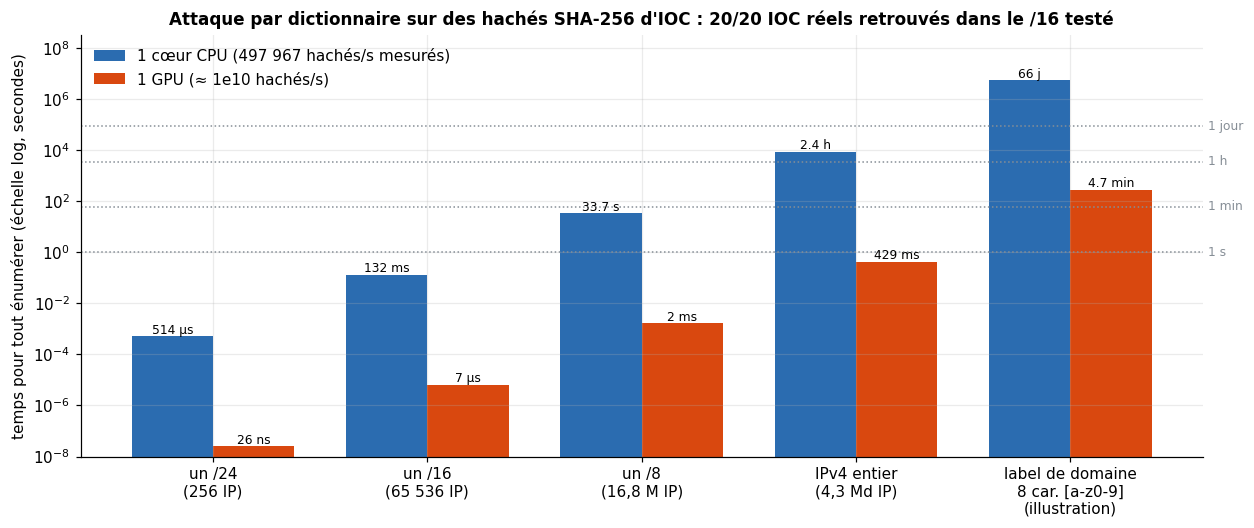

In [7]:
rate_cpu = 65536 / dt          # hachés/s mesurés à la section 2 (énumération du /16)
rate_gpu = 1e10
spaces = {
    "un /24\n(256 IP)": 2**8,
    "un /16\n(65 536 IP)": 2**16,
    "un /8\n(16,8 M IP)": 2**24,
    "IPv4 entier\n(4,3 Md IP)": 2**32,
    "label de domaine\n8 car. [a-z0-9]\n(illustration)": 36**8,
}
labels = list(spaces)
n_space = np.array(list(spaces.values()), dtype=float)
t_cpu, t_gpu = n_space / rate_cpu, n_space / rate_gpu
xx = np.arange(len(labels)); w = 0.38

fig, ax = plt.subplots(figsize=(11.5, 4.9))
ax.bar(xx - w / 2, t_cpu, w, color=C["bleu"], label=f"1 cœur CPU ({rate_cpu:,.0f} hachés/s mesurés)".replace(",", " "))
ax.bar(xx + w / 2, t_gpu, w, color=C["rouge"], label="1 GPU (≈ 1e10 hachés/s)")
ax.set_yscale("log")
ax.set_ylim(1e-8, max(t_cpu.max(), 1) * 60)
for xi, (a_, b_) in enumerate(zip(t_cpu, t_gpu)):
    ax.text(xi - w / 2, a_ * 1.25, fmt_t(a_), ha="center", fontsize=8)
    ax.text(xi + w / 2, b_ * 1.25, fmt_t(b_), ha="center", fontsize=8)
for yv, lab in ((1, "1 s"), (60, "1 min"), (3600, "1 h"), (86400, "1 jour")):
    ax.axhline(yv, color=C["gris"], ls=":", lw=1)
    ax.text(1.005, yv, lab, color=C["gris"], fontsize=8, ha="left", va="center", transform=ax.get_yaxis_transform())
ax.set_xticks(xx); ax.set_xticklabels(labels)
ax.set_ylabel("temps pour tout énumérer (échelle log, secondes)")
ax.set_title(f"Attaque par dictionnaire sur des hachés SHA-256 d'IOC : {len(recovered)}/{len(victim)} IOC réels retrouvés dans le /16 testé")
ax.legend(loc="upper left")
save_fig(fig, "fig01_attaque_dictionnaire")

## 3. Chiffrement homomorphe — PSI à base de chiffrement **additivement homomorphe** (Paillier, style Freedman–Nissim–Pinkas)

Paillier fournit $\mathrm{Enc}(m_1)\cdot\mathrm{Enc}(m_2)=\mathrm{Enc}(m_1+m_2)$ et $\mathrm{Enc}(m)^k=\mathrm{Enc}(km)$.

* Le client (`ORG_A`) hache ses IOC en racines de 40 bits $r_1..r_d$ et forme le polynôme $P(x)=\prod_i (x-r_i)$ (donc $P(r)=0 \iff r$ est une racine) ; il envoie les **coefficients chiffrés**.
* Pour chacun de ses éléments $y$, le serveur (`ORG_B`) évalue $\mathrm{Enc}(P(y))$ **de façon homomorphe** (Horner), puis renvoie $\mathrm{Enc}(\rho\cdot P(y) + y)$ avec un $\rho$ aléatoire frais.
* Le client déchiffre : si $P(y)=0$ il obtient $y$ lui-même (une racine → correspondance), sinon une valeur uniformément aléatoire.

**Binning** (Freedman et al.) : on répartit les racines dans $B$ casiers par haché, on complète chaque casier à la même taille $L$ avec des racines factices ; le serveur n'évalue que le polynôme du casier de $y$ → coût serveur $O(m\cdot L)$ au lieu de $O(m\cdot d)$.

Les deux ensembles sont les **sous-ensembles d'IOC réels** `X_real` / `Y_real` préparés en section 1c.

*Paramètre jouet :* module de 1024 bits ici pour garder le notebook rapide (utiliser ≥ 3072 bits en production). Hachés de 40 bits ⇒ probabilité de faux positif $\approx d\cdot m/2^{40}$.

In [8]:
def is_probable_prime(n: int, rounds: int = 24) -> bool:
    if n < 2: return False
    for sp in (2, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31, 37):
        if n % sp == 0: return n == sp
    d, s = n - 1, 0
    while d % 2 == 0: d //= 2; s += 1
    for _ in range(rounds):
        a = secrets.randbelow(n - 3) + 2
        x = pow(a, d, n)
        if x in (1, n - 1): continue
        for _ in range(s - 1):
            x = x * x % n
            if x == n - 1: break
        else:
            return False
    return True

def gen_prime(bits: int) -> int:
    while True:
        c = secrets.randbits(bits) | (1 << (bits - 1)) | 1
        if is_probable_prime(c, 20): return c

class Paillier:
    def __init__(self, bits: int = 1024):
        p = gen_prime(bits // 2)
        q = gen_prime(bits // 2)
        while q == p: q = gen_prime(bits // 2)
        self.n, self.n2 = p * q, (p * q) ** 2
        self.lam = math.lcm(p - 1, q - 1)
        self.mu = pow(self.lam, -1, self.n)                  # avec g = n+1 :  L(g^lam mod n^2) = lam
        self.ct_bytes = 2 * bits // 8

    def enc(self, m: int) -> int:
        r = secrets.randbelow(self.n - 1) + 1
        return (1 + m % self.n * self.n) * pow(r, self.n, self.n2) % self.n2

    def dec(self, c: int) -> int:
        return (pow(c, self.lam, self.n2) - 1) // self.n * self.mu % self.n

t0 = time.perf_counter(); HE = Paillier(1024); print(f"Génération de clés Paillier : {time.perf_counter() - t0:.2f} s")
c1, c2 = HE.enc(12345), HE.enc(678)
check("Paillier : Enc(a)*Enc(b) se déchiffre en a+b", HE.dec(c1 * c2 % HE.n2) == 12345 + 678)
check("Paillier : Enc(a)^k se déchiffre en k*a", HE.dec(pow(c1, 1000, HE.n2)) == 12345 * 1000)

Génération de clés Paillier : 0.10 s
[ok] Paillier : Enc(a)*Enc(b) se déchiffre en a+b
[ok] Paillier : Enc(a)^k se déchiffre en k*a


In [9]:
HBITS = 40
def h40(x: str) -> int:
    return int.from_bytes(hashlib.sha256(b"H40|" + x.encode()).digest()[:HBITS // 8], "big")

def poly_from_roots(roots, mod):
    coeffs = [1]                                              # degré croissant
    for r in roots:
        new = [0] * (len(coeffs) + 1)
        for i, c in enumerate(coeffs):
            new[i + 1] = (new[i + 1] + c) % mod
            new[i] = (new[i] - r * c) % mod
        coeffs = new
    return coeffs

def paillier_psi(he: Paillier, client_items, server_items, bins: int = 1):
    c_items, s_items = sorted(set(client_items)), sorted(set(server_items))
    t0 = time.perf_counter()
    hc = {h40(x): x for x in c_items}
    buckets = [[] for _ in range(bins)]
    for h in hc: buckets[h % bins].append(h)
    L = max(len(b) for b in buckets)
    for b in buckets:                                          # complète avec des racines factices (>= 2^40, ne peuvent pas collisionner avec de vrais hachés)
        while len(b) < L: b.append(secrets.randbits(HBITS) | (1 << HBITS))
    enc_polys = [[he.enc(c) for c in poly_from_roots(b, he.n)] for b in buckets]       # client -> serveur
    t_client1 = time.perf_counter() - t0

    t0 = time.perf_counter()
    answers = []
    for y in s_items:                                          # serveur : évaluation homomorphe de Horner + aveuglement
        hy = h40(y)
        coeffs = enc_polys[hy % bins]
        acc = coeffs[-1]
        for cj in reversed(coeffs[:-1]):
            acc = pow(acc, hy, he.n2) * cj % he.n2
        answers.append(pow(acc, secrets.randbits(128) | 1, he.n2) * he.enc(hy) % he.n2)
    _sysrand.shuffle(answers)
    t_server = time.perf_counter() - t0

    t0 = time.perf_counter()
    inter = []
    for ct in answers:                                         # client
        m = he.dec(ct)
        if m in hc: inter.append(hc[m])
    t_client2 = time.perf_counter() - t0
    nbytes = (bins * (L + 1) + len(answers)) * he.ct_bytes
    return {"intersection": sorted(inter), "time": t_client1 + t_server + t_client2,
            "phases": {"client_encrypt": t_client1, "server_eval": t_server, "client_decrypt": t_client2},
            "bytes": nbytes, "bin_size": L}

In [10]:
BINS = max(1, PSI_N // 8)
print(f"Paillier-PSI sur flux RÉELS | client={ORG_A} (|X|={len(X_real)}), serveur={ORG_B} (|Y|={len(Y_real)}), |X∩Y| réel={len(TRUTH)}")
r1 = paillier_psi(HE, X_real, Y_real, bins=1)
r2 = paillier_psi(HE, X_real, Y_real, bins=BINS)
print(f"1 casier   : {r1['time']:.2f} s  {r1['bytes'] / 1024:.0f} Kio  serveur={r1['phases']['server_eval']:.2f} s")
print(f"{BINS} casiers : {r2['time']:.2f} s  {r2['bytes'] / 1024:.0f} Kio  serveur={r2['phases']['server_eval']:.2f} s (taille de casier L={r2['bin_size']})")
check("Paillier-PSI (1 casier) == intersection en clair des flux réels", set(r1["intersection"]) == TRUTH)
check(f"Paillier-PSI ({BINS} casiers) == intersection en clair des flux réels", set(r2["intersection"]) == TRUTH)

PAILLIER_IOCS = r2["intersection"]                                # appris par ORG_A -> entrée de l'export STIX (section 6)
print("Types d'IOC trouvés par Paillier-PSI :", dict(Counter(x.split(":", 1)[0] for x in PAILLIER_IOCS)))

Paillier-PSI sur flux RÉELS | client=Phishing-domains (|X|=100), serveur=Phishing-links (|Y|=100), |X∩Y| réel=25


1 casier   : 11.80 s  50 Kio  serveur=8.84 s
12 casiers : 6.51 s  67 Kio  serveur=2.58 s (taille de casier L=13)
[ok] Paillier-PSI (1 casier) == intersection en clair des flux réels
[ok] Paillier-PSI (12 casiers) == intersection en clair des flux réels
Types d'IOC trouvés par Paillier-PSI : {'domain': 25}


### Graphe 2 — Paillier-PSI : effet du *binning* sur le temps et la communication

On exécute Paillier-PSI pour plusieurs nombres de casiers $B$ (les configurations `1 casier` et `BINS` réutilisent les résultats ci-dessus) et on vérifie à chaque fois que l'intersection obtenue est **exactement** la vérité terrain.

* **À gauche** : décomposition du temps (chiffrement client, évaluation homomorphe serveur, déchiffrement client). Le coût serveur domine et diminue avec $B$, car chaque élément n'évalue qu'un polynôme de degré $L \approx d/B$.
* **À droite** : le compromis — le calcul serveur baisse, mais la communication augmente légèrement (on envoie $B\,(L+1)$ chiffrés, avec des racines factices de remplissage).

[ok] Paillier-PSI : toutes les tailles de casiers testées retrouvent l'intersection réelle
 casiers   L  client_encrypt  server_eval  client_decrypt  total   Kio
       1 100            1.49         8.84            1.47  11.80 50.25
       2  50            1.50         5.31            1.43   8.24 50.50
       4  28            1.63         3.57            1.41   6.61 54.00
       8  19            2.31         2.99            1.44   6.74 65.00
      12  13            2.45         2.58            1.49   6.51 67.00
      25   9            3.57         2.32            1.46   7.35 87.50


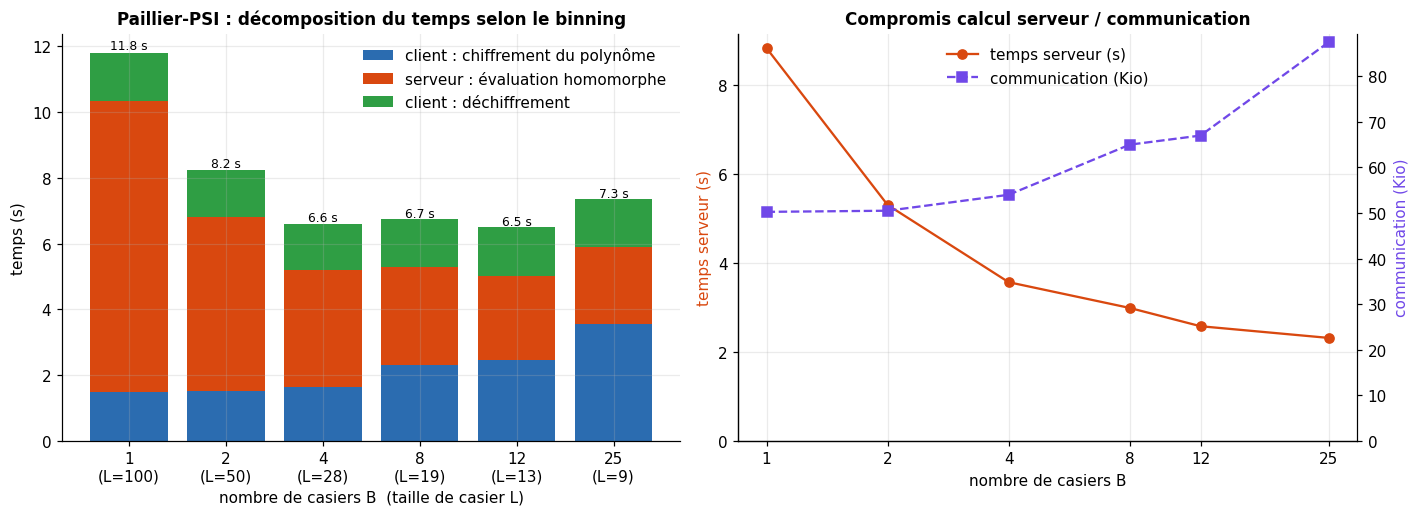

Gain du binning côté serveur : ×3.8 (de 8.84 s à 2.32 s), communication ×1.74


In [11]:
bins_list = sorted({1, 2, 4, 8, BINS, max(BINS, PSI_N // 4)})
sweep = {1: r1, BINS: r2}
for bn in bins_list:
    if bn not in sweep:
        sweep[bn] = paillier_psi(HE, X_real, Y_real, bins=bn)
check("Paillier-PSI : toutes les tailles de casiers testées retrouvent l'intersection réelle",
      all(set(s["intersection"]) == TRUTH for s in sweep.values()))

df_sw = pd.DataFrame([{"casiers": bn, "L": s["bin_size"], "client_encrypt": s["phases"]["client_encrypt"],
                       "server_eval": s["phases"]["server_eval"], "client_decrypt": s["phases"]["client_decrypt"],
                       "total": s["time"], "Kio": s["bytes"] / 1024} for bn, s in sorted(sweep.items())])
print(df_sw.round(2).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
ax = axes[0]
xs = np.arange(len(df_sw)); bottom = np.zeros(len(df_sw))
for col, lab, colr in (("client_encrypt", "client : chiffrement du polynôme", C["bleu"]),
                       ("server_eval", "serveur : évaluation homomorphe", C["rouge"]),
                       ("client_decrypt", "client : déchiffrement", C["vert"])):
    ax.bar(xs, df_sw[col], bottom=bottom, label=lab, color=colr)
    bottom += df_sw[col].values
for x_, t_ in zip(xs, bottom):
    ax.text(x_, t_ * 1.01, f"{t_:.1f} s", ha="center", fontsize=8)
ax.set_xticks(xs)
ax.set_xticklabels([f"{int(r.casiers)}\n(L={int(r.L)})" for r in df_sw.itertuples()])
ax.set_xlabel("nombre de casiers B  (taille de casier L)")
ax.set_ylabel("temps (s)")
ax.set_title("Paillier-PSI : décomposition du temps selon le binning")
ax.legend()

ax = axes[1]
ax.plot(df_sw.casiers, df_sw.server_eval, "o-", color=C["rouge"], label="temps serveur (s)")
ax.set_xscale("log", base=2)
ax.set_xticks(list(df_sw.casiers)); ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{int(v)}"))
ax.xaxis.set_minor_locator(NullLocator())
ax.set_xlabel("nombre de casiers B")
ax.set_ylabel("temps serveur (s)", color=C["rouge"])
ax2 = ax.twinx()
ax2.plot(df_sw.casiers, df_sw.Kio, "s--", color=C["violet"], label="communication (Kio)")
ax2.set_ylabel("communication (Kio)", color=C["violet"]); ax2.grid(False); ax2.spines["right"].set_visible(True)
lines = ax.get_lines() + ax2.get_lines()
ax.legend(lines, [l.get_label() for l in lines], loc="upper center")
ax.set_ylim(bottom=0); ax2.set_ylim(bottom=0)
ax.set_title("Compromis calcul serveur / communication")
save_fig(fig, "fig02_paillier_binning")

gain = df_sw.server_eval.iloc[0] / df_sw.server_eval.min()
print(f"Gain du binning côté serveur : ×{gain:.1f} (de {df_sw.server_eval.iloc[0]:.2f} s à {df_sw.server_eval.min():.2f} s), "
      f"communication ×{df_sw.Kio.iloc[df_sw.server_eval.idxmin()] / df_sw.Kio.iloc[0]:.2f}")

## 4. Post-quantique — esquisse de PSI à base de réseaux (LWE) : filtre de Bloom chiffré  *(**paramètres jouets**)*

Paillier-PSI (factorisation) et DH-PSI (log discret) tombent tous deux face à l'algorithme de Shor. On construit ici un PSI dont la seule hypothèse de difficulté est **LWE**.

**Chiffrement LWE à clé secrète d'un bit / petit entier** $v\in\mathbb{Z}_t$ :
$\;\mathbf{c}=(\mathbf{a},\ b=\langle\mathbf{a},\mathbf{s}\rangle+e+\Delta v \bmod q)$ avec $\Delta=\lfloor q/t\rfloor$ et un petit bruit $e$.
Il est **additivement homomorphe** : la somme de $k$ chiffrés est un chiffré de la somme des clairs (le bruit s'additionne, il faut donc $k\cdot|e|\ll\Delta/2$).

**Protocole (rôles : le *propriétaire* détient la clé secrète, l'*évaluateur* calcule sur les chiffrés) :**
1. Le propriétaire (`ORG_B`) insère ses IOC dans un filtre de Bloom (m bits, k positions de hachage), chiffre en LWE **chaque bit**, et envoie $(\text{graine de }\mathbf{A},\ \mathbf{b})$ — $\mathbf{A}$ est un aléa public, il est donc envoyé sous forme de courte graine.
2. Pour chacun de ses IOC $y$, l'évaluateur (`ORG_A`) **additionne les k chiffrés** aux positions de Bloom de $y$ → un chiffré de « combien de ces k bits sont à 1 » ; il envoie tous les résultats **mélangés**.
3. Le propriétaire déchiffre ; un compte égal à $k$ signifie « probablement dans l'ensemble du propriétaire ». Il renvoie les indices de ces réponses → l'**évaluateur apprend l'intersection** ; le propriétaire n'apprend que (approximativement) sa taille.

Comme en section 3, `ORG_A` est la partie qui apprend l'intersection, et les deux parties utilisent les **sous-ensembles réels** `X_real` / `Y_real`.

**Réserves honnêtes (à discuter dans le rapport) :** (i) le propriétaire voit le compte de correspondances partielles de chaque élément de l'évaluateur (petite fuite supplémentaire, quantifiée ci-dessous) ;
(ii) faux positifs du filtre de Bloom, qu'un SOC ne peut pas distinguer de vraies correspondances (taux quantifié ci-dessous) ;
(iii) les paramètres $n=256$, $q=2^{32}$, $\sigma=2^{10}$ sont des *jouets* — utiliser le lattice-estimator pour choisir des valeurs réelles (Kyber utilise $n=256$ avec une structure *modulaire* et $q=3329$) ;
(iv) le PRNG de NumPy sert à tirer le secret et le bruit : acceptable pour une démo, **pas** pour la production, qui exige un CSPRNG et une implémentation à temps constant ;
(v) les systèmes réels (p. ex. Microsoft APSI) utilisent du FHE de type BFV/CKKS avec empaquetage SIMD pour obtenir un résultat exact, sans fuite et beaucoup plus compact.

In [12]:
LWE_Q = 1 << 32

def bloom_positions(item: str, m_bits: int, k: int):
    pos, ctr = [], 0
    while len(pos) < k:
        h = int.from_bytes(hashlib.sha256(f"{ctr}|{item}".encode()).digest()[:8], "big") % m_bits
        if h not in pos: pos.append(h)
        ctr += 1
    return pos

def lwe_bloom_psi(owner_items, evaluator_items, k: int = 7, ratio: int = 40, n: int = 256, sigma: float = 1024.0, t: int = 16):
    delta = LWE_Q // t
    o, ev = sorted(set(owner_items)), sorted(set(evaluator_items))
    m_bits = ratio * len(o)
    seed = secrets.randbits(63)
    T = {}
    # --- propriétaire : construit + chiffre le filtre de Bloom
    t0 = time.perf_counter()
    A = np.random.default_rng(seed).integers(0, LWE_Q, size=(m_bits, n), dtype=np.int64)
    rng = np.random.default_rng(secrets.randbits(63))
    s = rng.integers(-1, 2, size=n, dtype=np.int64)                              # secret ternaire
    err = np.rint(rng.normal(0, sigma, size=m_bits)).astype(np.int64)
    bits = np.zeros(m_bits, dtype=np.int64)
    for x in o: bits[bloom_positions(x, m_bits, k)] = 1
    b = (A @ s + err + delta * bits) % LWE_Q
    T["owner_encrypt"] = time.perf_counter() - t0
    # --- évaluateur : sommes homomorphes sur les k positions de chacun de ses éléments
    t0 = time.perf_counter()
    A_e = np.random.default_rng(seed).integers(0, LWE_Q, size=(m_bits, n), dtype=np.int64)   # régénérée à partir de la graine publique
    P = np.array([bloom_positions(y, m_bits, k) for y in ev])
    A_sum = A_e[P].sum(axis=1) % LWE_Q
    b_sum = b[P].sum(axis=1) % LWE_Q
    perm = np.array(_sysrand.sample(range(len(ev)), len(ev)))                    # mélange des réponses
    A_sum, b_sum = A_sum[perm], b_sum[perm]
    T["evaluator"] = time.perf_counter() - t0
    # --- propriétaire : déchiffre
    t0 = time.perf_counter()
    v = (b_sum - A_sum @ s) % LWE_Q
    counts = ((v + delta // 2) // delta) % t
    match_idx = np.nonzero(counts == k)[0]
    T["owner_decrypt"] = time.perf_counter() - t0
    inter = [ev[perm[i]] for i in match_idx]                                     # l'évaluateur retrouve les éléments (il connaît perm)
    expected = bits[P].sum(axis=1)[perm]                                         # ce que donnerait un filtre de Bloom en clair
    nbytes = 8 + m_bits * 4 + len(ev) * (n + 1) * 4 + len(match_idx) * 4
    return {"intersection": sorted(inter), "time": sum(T.values()), "phases": T, "bytes": nbytes,
            "counts": counts, "expected_counts": expected, "m_bits": m_bits, "k": k, "n_owner": len(o)}

In [13]:
print(f"LWE-Bloom-PSI sur flux RÉELS | propriétaire={ORG_B} (|Y|={len(Y_real)}), évaluateur={ORG_A} (|X|={len(X_real)}), |X∩Y| réel={len(TRUTH)}")
rl = lwe_bloom_psi(owner_items=Y_real, evaluator_items=X_real)
LWE_IOCS = rl["intersection"]                                                    # appris par ORG_A -> entrée de l'export STIX (section 6)
fp = set(LWE_IOCS) - TRUTH
fp_rate = (1 - math.exp(-rl["k"] * rl["n_owner"] / rl["m_bits"])) ** rl["k"]
print(f"trouvés={len(LWE_IOCS)}, |X∩Y| réel={len(TRUTH)}, faux positifs={len(fp)} | {rl['time']:.2f} s | {rl['bytes'] / 1024:.0f} Kio")
print(f"Paramètres de Bloom : m={rl['m_bits']} bits, k={rl['k']}, taux de FP théorique ≈ {fp_rate:.1e} par élément de l'évaluateur")
check("le déchiffrement homomorphe LWE est exact (égal aux comptes d'un Bloom en clair)", np.array_equal(rl["counts"], rl["expected_counts"]))
check("LWE-PSI retrouve tous les éléments de l'intersection réelle (aucun faux négatif)", TRUTH <= set(LWE_IOCS))
check("Paillier-PSI et LWE-PSI s'accordent sur l'intersection réelle (aux faux positifs de Bloom près)", set(PAILLIER_IOCS) == TRUTH and set(PAILLIER_IOCS) <= set(LWE_IOCS))

LWE-Bloom-PSI sur flux RÉELS | propriétaire=Phishing-links (|Y|=100), évaluateur=Phishing-domains (|X|=100), |X∩Y| réel=25
trouvés=25, |X∩Y| réel=25, faux positifs=0 | 0.01 s | 116 Kio
Paramètres de Bloom : m=4000 bits, k=7, taux de FP théorique ≈ 2.7e-06 par élément de l'évaluateur
[ok] le déchiffrement homomorphe LWE est exact (égal aux comptes d'un Bloom en clair)
[ok] LWE-PSI retrouve tous les éléments de l'intersection réelle (aucun faux négatif)
[ok] Paillier-PSI et LWE-PSI s'accordent sur l'intersection réelle (aux faux positifs de Bloom près)


In [14]:
# Quantification de la fuite supplémentaire : le propriétaire voit le nombre de positions de Bloom à 1 pour chaque élément (mélangé) de l'évaluateur
k_lwe = rl["k"]
hist = np.bincount(rl["counts"], minlength=k_lwe + 1)
leak = pd.DataFrame({"compte déchiffré (sur k)": range(len(hist)), "# éléments de l'évaluateur": hist,
                     "part": (hist / hist.sum()).round(3)})
print(leak.to_string(index=False))
non_member_mean = rl["counts"][rl["counts"] < k_lwe].mean()
print(f"\nLes éléments au compte = k sont les correspondances ({int((rl['counts'] == k_lwe).sum())}). Les non-membres ont en moyenne {non_member_mean:.2f} positions à 1 sur {k_lwe} :")
print("le propriétaire apprend tout cet histogramme, soit une information au-delà de |X ∩ Y| ; un PSI exact à base de FHE supprime cette fuite.")

 compte déchiffré (sur k)  # éléments de l'évaluateur  part
                        0                          23  0.23
                        1                          22  0.22
                        2                          20  0.20
                        3                           8  0.08
                        4                           2  0.02
                        5                           0  0.00
                        6                           0  0.00
                        7                          25  0.25

Les éléments au compte = k sont les correspondances (25). Les non-membres ont en moyenne 1.25 positions à 1 sur 7 :
le propriétaire apprend tout cet histogramme, soit une information au-delà de |X ∩ Y| ; un PSI exact à base de FHE supprime cette fuite.


### Graphe 3 — LWE/Bloom : fuite des comptes partiels et faux positifs

* **À gauche** : histogramme des comptes déchiffrés (nombre de positions de Bloom à 1 parmi $k$) pour chaque élément de l'évaluateur. Les éléments à $k/k$ sont les correspondances (vert) ; les autres suivent approximativement une loi **binomiale** $\mathcal{B}(k, f)$ où $f = 1 - e^{-kn/m}$ est le taux de remplissage du filtre (points noirs, valeurs théoriques). C'est précisément cette distribution que le propriétaire apprend en plus de $|X\cap Y|$.
* **À droite** : taux théorique de faux positifs $(1 - e^{-k n/m})^k$ en fonction du rapport $m/n$ pour plusieurs valeurs de $k$ ; le point rouge indique les paramètres utilisés dans ce notebook.

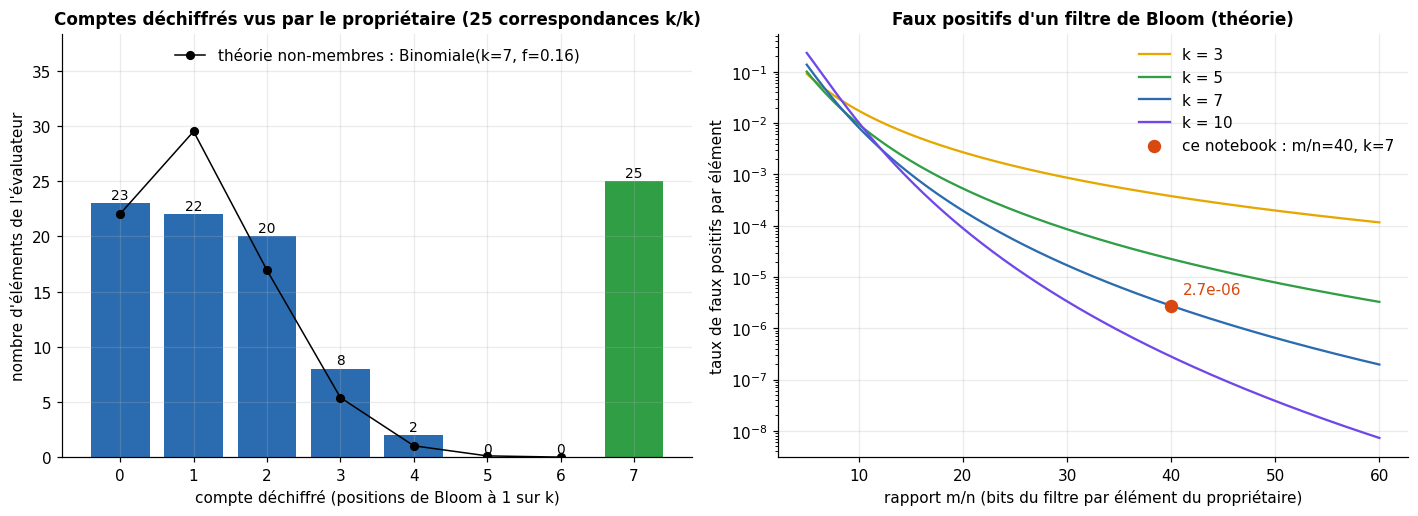

Taux de remplissage théorique du filtre f = 0.161 ; faux positifs observés : 0 / 75 non-membres


In [15]:
k_lwe = rl["k"]; cnt = rl["counts"]
n_eval = len(cnt)
n_match = int((cnt == k_lwe).sum())
fill = 1 - math.exp(-rl["k"] * rl["n_owner"] / rl["m_bits"])                   # taux de remplissage du filtre
pmf = np.array([math.comb(k_lwe, j) * fill**j * (1 - fill)**(k_lwe - j) for j in range(k_lwe + 1)])
hist = np.bincount(cnt, minlength=k_lwe + 1)
expected_nonmember = (n_eval - len(TRUTH)) * pmf                               # espérance pour les non-membres

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
ax = axes[0]
cols = [C["bleu"]] * k_lwe + [C["vert"]]
ax.bar(range(k_lwe + 1), hist, color=cols)
ax.plot(range(k_lwe), expected_nonmember[:k_lwe], "ko-", ms=5, lw=1, label=f"théorie non-membres : Binomiale(k={k_lwe}, f={fill:.2f})")
for j, v in enumerate(hist):
    ax.text(j, v + 0.4, str(int(v)), ha="center", fontsize=9)
ax.set_xlabel("compte déchiffré (positions de Bloom à 1 sur k)")
ax.set_ylabel("nombre d'éléments de l'évaluateur")
ax.set_title(f"Comptes déchiffrés vus par le propriétaire ({n_match} correspondances k/k)")
ax.set_xticks(range(k_lwe + 1))
ax.set_ylim(top=max(hist.max(), expected_nonmember.max()) * 1.3)
ax.legend(loc="upper center")

ax = axes[1]
ratios = np.linspace(5, 60, 300)
for kk, colr in ((3, C["or"]), (5, C["vert"]), (7, C["bleu"]), (10, C["violet"])):
    ax.plot(ratios, (1 - np.exp(-kk / ratios)) ** kk, color=colr, label=f"k = {kk}")
ratio_used = rl["m_bits"] / rl["n_owner"]
ax.scatter([ratio_used], [fp_rate], color=C["rouge"], zorder=5, s=60, label=f"ce notebook : m/n={ratio_used:.0f}, k={k_lwe}")
ax.annotate(f"{fp_rate:.1e}", (ratio_used, fp_rate), textcoords="offset points", xytext=(8, 8), color=C["rouge"])
ax.set_yscale("log")
ax.set_xlabel("rapport m/n (bits du filtre par élément du propriétaire)")
ax.set_ylabel("taux de faux positifs par élément")
ax.set_title("Faux positifs d'un filtre de Bloom (théorie)")
ax.legend()
save_fig(fig, "fig03_lwe_fuite_et_faux_positifs")

print(f"Taux de remplissage théorique du filtre f = {fill:.3f} ; faux positifs observés : {len(set(LWE_IOCS) - TRUTH)} / {n_eval - len(TRUTH)} non-membres")

## 5. Divulgation nulle — prouver que le serveur a utilisé **une seule clé cohérente** (Chaum–Pedersen DLEQ batché)

### 5.1 Groupe cryptographique : nombre premier sûr, hachage vers le groupe
On travaille dans le sous-groupe $\mathbb{G}$ des résidus quadratiques de $\mathbb{Z}_p^*$ pour un **nombre premier sûr** $p = 2q+1$ ; $\mathbb{G}$ est d'ordre premier $q$.
On utilise le **groupe MODP 2048 bits de la RFC 3526**, dont le premier est *défini par une formule* faisant intervenir $\pi$ — on le recalcule avec `mpmath` et on le vérifie, au lieu de coller 600 chiffres hexadécimaux.

`hash_to_group(x)` étend `x` avec SHAKE-256 sur $>|p|$ bits, réduit modulo $p$ puis **élève au carré** : le résultat tombe dans $\mathbb{G}$ et se comporte comme un oracle aléatoire vers le groupe.
La sécurité de l'aveuglement commutatif repose sur **DDH/CDH dans $\mathbb{G}$** + le modèle de l'oracle aléatoire pour ce hachage.

In [16]:
def rfc3526_prime_2048() -> int:
    mp.prec = 2300
    pi_term = int(mp.floor(mp.mpf(2) ** 1918 * mp.pi))
    return 2**2048 - 2**1984 - 1 + 2**64 * (pi_term + 124476)

@dataclass
class Group:
    p: int
    q: int
    g: int
    exp_bits: int = 256                       # exposants courts (pratique standard) -> ~7x plus rapide qu'avec des exposants pleine taille

    def __post_init__(self):
        self.byte_len = (self.p.bit_length() + 7) // 8

    def hash_to_group(self, s: str) -> int:
        h = hashlib.shake_256(b"H2G|" + s.encode()).digest(self.byte_len + 16)
        return pow(int.from_bytes(h, "big") % self.p, 2, self.p)

    def rand_exp(self) -> int:
        bits = min(self.exp_bits, self.q.bit_length() - 1)
        while True:
            e = secrets.randbits(bits)
            if 1 < e < self.q: return e

    def pow(self, x: int, e: int) -> int:
        return pow(x, e, self.p)

    def in_subgroup(self, x: int) -> bool:
        return 1 < x < self.p and pow(x, self.q, self.p) == 1

    def encode(self, x: int) -> bytes:
        return x.to_bytes(self.byte_len, "big")

t0 = time.perf_counter()
P2048 = rfc3526_prime_2048()
Q2048 = (P2048 - 1) // 2
check("le premier RFC3526 a les 64 bits de tête et de queue attendus",
      hex(P2048)[2:34] == "ffffffffffffffffc90fdaa22168c234" and P2048 % 2**64 == 2**64 - 1)
check("p et q=(p-1)/2 sont premiers (premier sûr)", is_probable_prime(P2048, 10) and is_probable_prime(Q2048, 10))
G = Group(P2048, Q2048, 4)
check("le générateur g=4 appartient au sous-groupe d'ordre q", G.in_subgroup(G.g))
print(f"Groupe prêt en {time.perf_counter() - t0:.2f} s | |p|={P2048.bit_length()} bits | taille d'exposant={G.exp_bits} bits")

a, b = G.rand_exp(), G.rand_exp()
h = G.hash_to_group("ip:1.2.3.4")
check("commutativité (H(x)^a)^b == (H(x)^b)^a", G.pow(G.pow(h, a), b) == G.pow(G.pow(h, b), a))
t0 = time.perf_counter(); [G.pow(h, a) for _ in range(200)]; print(f"une exponentiation modulaire 2048 bits (exposant 256 bits) : {(time.perf_counter() - t0) / 200 * 1000:.2f} ms")

[ok] le premier RFC3526 a les 64 bits de tête et de queue attendus


[ok] p et q=(p-1)/2 sont premiers (premier sûr)
[ok] le générateur g=4 appartient au sous-groupe d'ordre q
Groupe prêt en 0.59 s | |p|=2048 bits | taille d'exposant=256 bits
[ok] commutativité (H(x)^a)^b == (H(x)^b)^a


une exponentiation modulaire 2048 bits (exposant 256 bits) : 3.63 ms


### 5.2 Transcription DH-PSI minimale (l'énoncé à prouver)
On ne garde de DH-PSI que ce qui est nécessaire pour produire la transcription sur laquelle la preuve sera testée. Le client (`ORG_A`) aveugle ses IOC **réels** avec son secret $a$, puis le serveur les aveugle à nouveau avec son secret $b$ :

1. Client → Serveur : $A_i = H(x_i)^a$.
2. Serveur → Client : $B_i = A_i^{\,b} = H(x_i)^{ab}$.

Un serveur malveillant pourrait élever des éléments différents avec des clés différentes (ou renvoyer n'importe quoi) pour biaiser le résultat ou monter des tests contre le client.
Le serveur publie donc $pk = g^b$ et doit **prouver en divulgation nulle** que chaque $B_i$ a été calculé avec le *même* $b$.

In [17]:
def dh_psi_transcript(G: Group, client_items):
    """Tours 1-2 de DH-PSI sur les IOC du client : retourne la transcription (A, B) et la clé serveur b (utile seulement au prouveur)."""
    c_items = sorted(set(client_items))
    a, b = G.rand_exp(), G.rand_exp()
    A = [G.pow(G.hash_to_group(x), a) for x in c_items]                       # client -> serveur
    B = [G.pow(v, b) for v in A]                                              # serveur -> client
    return A, B, b

t0 = time.perf_counter()
A_msgs, B_msgs, b_srv = dh_psi_transcript(G, X_real)                          # IOC réels de ORG_A
print(f"Transcription DH-PSI sur {len(A_msgs)} IOC réels de {ORG_A} : {time.perf_counter() - t0:.2f} s")

Transcription DH-PSI sur 100 IOC réels de Phishing-domains : 0.73 s


### 5.3 Chaum–Pedersen DLEQ batché

$$\mathrm{DLEQ} :\ \log_g(pk)=\log_{A_i}(B_i)\quad \forall i .$$

Batching : on dérive des poids $\rho_i$ de 128 bits par Fiat–Shamir à partir de tous les $(A_i,B_i)$, on pose $A^*=\prod A_i^{\rho_i}$, $B^*=\prod B_i^{\rho_i}$ et on prouve **un seul** DLEQ pour $(g,pk,A^*,B^*)$ — si un seul $B_i$ est faux, la vérification échoue sauf avec probabilité $\approx 2^{-128}$.
Protocole sigma rendu non interactif par Fiat–Shamir (Ch. 4) ; la réponse $s=r+c\cdot b$ est calculée sur les entiers avec $r$ très supérieur à $c\cdot b$ → divulgation nulle statistique.

In [18]:
def _h_int(*parts, bits=128) -> int:
    h = hashlib.sha256()
    for p in parts:
        h.update(str(p).encode()); h.update(b"|")
    return int.from_bytes(h.digest(), "big") >> (256 - bits)

def _batch_combine(G: Group, pk, A, B):
    h = hashlib.sha256(G.encode(pk))
    for v in A: h.update(G.encode(v))
    for v in B: h.update(G.encode(v))
    seed = h.digest()
    Ac = Bc = 1
    for i, (x, y) in enumerate(zip(A, B)):
        rho = int.from_bytes(hashlib.sha256(seed + i.to_bytes(4, "big")).digest()[:16], "big")
        Ac = Ac * pow(x, rho, G.p) % G.p
        Bc = Bc * pow(y, rho, G.p) % G.p
    return Ac, Bc

def dleq_prove_batch(G: Group, b: int, A, B):
    pk = pow(G.g, b, G.p)
    Ac, Bc = _batch_combine(G, pk, A, B)
    r = secrets.randbits(b.bit_length() + 256)
    t1, t2 = pow(G.g, r, G.p), pow(Ac, r, G.p)
    c = _h_int("dleq", pk, Ac, Bc, t1, t2)
    return {"pk": pk, "t1": t1, "t2": t2, "s": r + c * b}

def dleq_verify_batch(G: Group, proof, A, B) -> bool:
    pk, t1, t2, s = proof["pk"], proof["t1"], proof["t2"], proof["s"]
    if not G.in_subgroup(pk): return False
    Ac, Bc = _batch_combine(G, pk, A, B)
    c = _h_int("dleq", pk, Ac, Bc, t1, t2)
    return pow(G.g, s, G.p) == t1 * pow(pk, c, G.p) % G.p and pow(Ac, s, G.p) == t2 * pow(Bc, c, G.p) % G.p

t0 = time.perf_counter(); proof = dleq_prove_batch(G, b_srv, A_msgs, B_msgs); tp = time.perf_counter() - t0
t0 = time.perf_counter(); ok = dleq_verify_batch(G, proof, A_msgs, B_msgs); tv = time.perf_counter() - t0
proof_kib = (3 * G.byte_len + proof["s"].bit_length() // 8) / 1024
print(f"preuve pour {len(A_msgs)} éléments : génération {tp:.2f} s, vérification {tv:.2f} s, taille ≈ {proof_kib:.1f} Kio (constante)")
check("serveur honnête : la preuve DLEQ est valide", ok)

B_bad = list(B_msgs)
B_bad[len(B_bad) // 2] = G.pow(B_bad[len(B_bad) // 2], 3)                       # le serveur triche sur un seul élément
check("serveur tricheur (1 élément avec une autre clé) : preuve rejetée", not dleq_verify_batch(G, proof, A_msgs, B_bad))
proof_bad = dleq_prove_batch(G, b_srv, A_msgs, B_bad)
check("le serveur tricheur ne peut pas produire de preuve valide après coup", not dleq_verify_batch(G, proof_bad, A_msgs, B_bad))

preuve pour 100 éléments : génération 0.43 s, vérification 0.48 s, taille ≈ 0.8 Kio (constante)
[ok] serveur honnête : la preuve DLEQ est valide


[ok] serveur tricheur (1 élément avec une autre clé) : preuve rejetée


[ok] le serveur tricheur ne peut pas produire de preuve valide après coup


### Graphe 4 — Preuve DLEQ batchée : taille constante, temps linéaire

On compare, pour différents nombres $n$ d'éléments de la transcription DH-PSI :

* **la preuve batchée** (une seule preuve pour tous les $(A_i, B_i)$, section 5.3) ;
* **une preuve DLEQ individuelle par élément** (approche naïve).

Le temps croît linéairement dans les deux cas (chaque élément doit être exponentié), mais la version batchée est nettement plus rapide (exposants de 128 bits pour les poids $\rho_i$ au lieu de $n$ preuves complètes) et surtout sa **taille est constante** alors qu'elle est linéaire pour les preuves individuelles — c'est le vrai gain du batching.

[ok] DLEQ : les preuves batchées et individuelles sont valides pour toutes les tailles testées
  n  batch_prove  batch_verify  indiv_prove  indiv_verify  batch_Kio  indiv_Kio
 10        0.055         0.087        0.201         0.537      0.812      8.117
 25        0.111         0.145        0.502         1.263      0.812     20.301
 50        0.206         0.237        1.007         2.502      0.812     40.602
 75        0.311         0.339        1.492         3.700      0.812     60.899
100        0.397         0.428        2.021         5.445      0.812     81.189


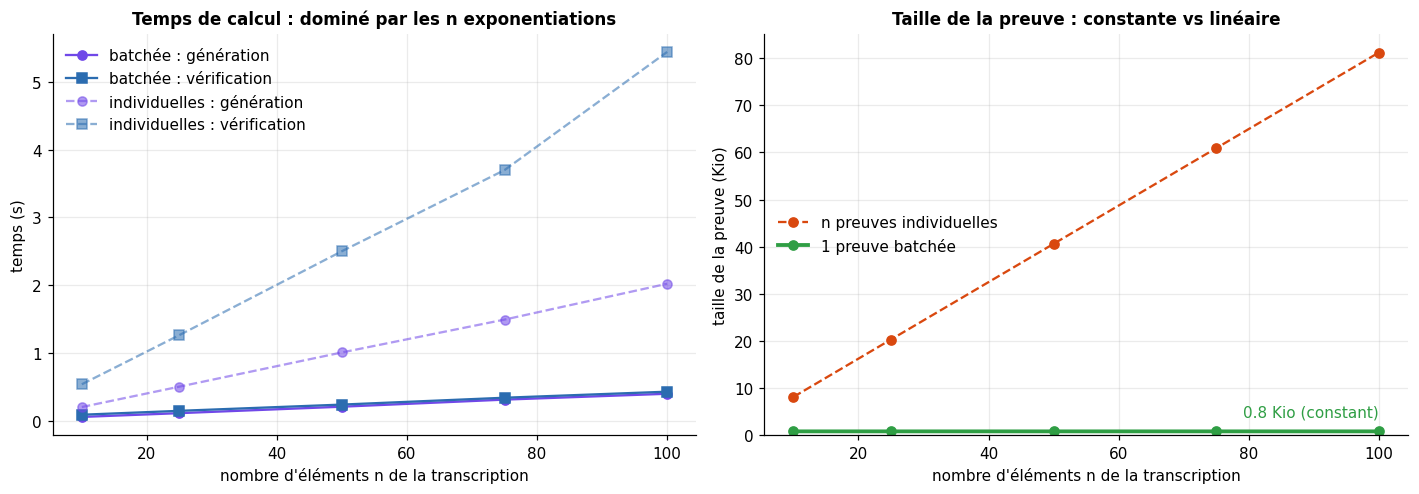

Pour n=100 : 100× moins d'octets à envoyer avec la preuve batchée.


In [19]:
def _proof_kib(pr):
    return (3 * G.byte_len + pr["s"].bit_length() // 8) / 1024

sizes_dl = [s for s in (10, 25, 50, 75, len(A_msgs)) if s <= len(A_msgs)]
sizes_dl = sorted(set(sizes_dl))
rows, all_valid = [], True
for nn in sizes_dl:
    An, Bn = A_msgs[:nn], B_msgs[:nn]
    t0 = time.perf_counter(); pr = dleq_prove_batch(G, b_srv, An, Bn); t_p = time.perf_counter() - t0
    t0 = time.perf_counter(); ok_b = dleq_verify_batch(G, pr, An, Bn); t_v = time.perf_counter() - t0
    t0 = time.perf_counter(); singles = [dleq_prove_batch(G, b_srv, [x_], [y_]) for x_, y_ in zip(An, Bn)]; t_ps = time.perf_counter() - t0
    t0 = time.perf_counter(); ok_s = all(dleq_verify_batch(G, s_, [x_], [y_]) for s_, x_, y_ in zip(singles, An, Bn)); t_vs = time.perf_counter() - t0
    all_valid &= bool(ok_b and ok_s)
    rows.append({"n": nn, "batch_prove": t_p, "batch_verify": t_v, "indiv_prove": t_ps, "indiv_verify": t_vs,
                 "batch_Kio": _proof_kib(pr), "indiv_Kio": sum(_proof_kib(s_) for s_ in singles)})
df_dl = pd.DataFrame(rows)
check("DLEQ : les preuves batchées et individuelles sont valides pour toutes les tailles testées", all_valid)
print(df_dl.round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
ax = axes[0]
ax.plot(df_dl.n, df_dl.batch_prove, "o-", color=C["violet"], label="batchée : génération")
ax.plot(df_dl.n, df_dl.batch_verify, "s-", color=C["bleu"], label="batchée : vérification")
ax.plot(df_dl.n, df_dl.indiv_prove, "o--", color=C["violet"], alpha=.55, label="individuelles : génération")
ax.plot(df_dl.n, df_dl.indiv_verify, "s--", color=C["bleu"], alpha=.55, label="individuelles : vérification")
ax.set_xlabel("nombre d'éléments n de la transcription"); ax.set_ylabel("temps (s)")
ax.set_title("Temps de calcul : dominé par les n exponentiations")
ax.legend()

ax = axes[1]
ax.plot(df_dl.n, df_dl.indiv_Kio, "o--", color=C["rouge"], label="n preuves individuelles")
ax.plot(df_dl.n, df_dl.batch_Kio, "o-", color=C["vert"], lw=2.5, label="1 preuve batchée")
ax.set_ylim(bottom=0)
ax.text(df_dl.n.iloc[-1], df_dl.batch_Kio.iloc[-1] + df_dl.indiv_Kio.max() * 0.04,
        f"{df_dl.batch_Kio.iloc[-1]:.1f} Kio (constant)", ha="right", color=C["vert"])
ax.set_xlabel("nombre d'éléments n de la transcription"); ax.set_ylabel("taille de la preuve (Kio)")
ax.set_title("Taille de la preuve : constante vs linéaire")
ax.legend(loc="center left")
save_fig(fig, "fig04_dleq_batch")

print(f"Pour n={df_dl.n.iloc[-1]} : {df_dl.indiv_Kio.iloc[-1] / df_dl.batch_Kio.iloc[-1]:.0f}× moins d'octets à envoyer avec la preuve batchée.")

## 6. Interopérabilité — export **STIX 2.1** de bout en bout des résultats du PSI

Les intersections apprises par `ORG_A` via **Paillier-PSI** et **LWE-PSI** (sections 3 et 4) sont converties en un **bundle STIX 2.1** qu'un SIEM/TIP (MISP, OpenCTI, Sentinel…) peut ingérer, p. ex. via TAXII :

* un objet `identity` pour l'organisation qui produit le renseignement (`created_by_ref`) ;
* un `indicator` par IOC, avec un pattern STIX valide (les littéraux de chaîne sont échappés), le contexte que `ORG_A` détient déjà localement (étiquette du flux, confiance, date de première observation comme `valid_from`) et des labels indiquant **quel protocole PSI l'a confirmé**. Un IOC confirmé par les deux protocoles donne **un seul** indicateur (UUIDv5 déterministe → un ré-export est idempotent et le TIP déduplique) ;
* LWE-PSI est probabiliste (faux positifs de Bloom), ce qui est indiqué dans la description de chaque indicateur.

Le bundle est écrit sur disque, **relu comme le ferait un consommateur SOC**, validé (structure, patterns) puis comparé aux sorties du PSI : rien n'est perdu et rien n'est ajouté en route.
Seuls les IOC de l'intersection sont exportés ; le reste des listes privées ne quitte jamais les organisations.

In [20]:
STIX_NS = uuid.uuid5(uuid.NAMESPACE_DNS, "psi-threat-intel.inpt.local")       # espace de noms fixe -> identifiants d'indicateurs déterministes
STIX_PATH = "psi_threat_intel_bundle.json"

def stix_now() -> str:
    return datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%dT%H:%M:%S.000Z")

def _stix_escape(v: str) -> str:
    return v.replace("\\", "\\\\").replace("'", "\\'")

def _stix_unescape(v: str) -> str:
    return re.sub(r"\\(['\\])", r"\1", v)

def to_stix_pattern(ioc: str) -> str:
    kind, val = ioc.split(":", 1)
    v = _stix_escape(val)
    return {"ip": f"[{'ipv6-addr' if ':' in val else 'ipv4-addr'}:value = '{v}']",
            "domain": f"[domain-name:value = '{v}']",
            "sha256": f"[file:hashes.'SHA-256' = '{v}']",
            "url": f"[url:value = '{v}']"}[kind]

_PATTERN_RES = [("ip", re.compile(r"^\[(?:ipv4-addr|ipv6-addr):value = '(.*)'\]$")),
                ("domain", re.compile(r"^\[domain-name:value = '(.*)'\]$")),
                ("sha256", re.compile(r"^\[file:hashes\.'SHA-256' = '(.*)'\]$")),
                ("url", re.compile(r"^\[url:value = '(.*)'\]$"))]

def ioc_from_stix_pattern(pattern: str) -> str:
    """Inverse de to_stix_pattern : ce qu'un consommateur SOC extrait d'un indicateur."""
    for kind, rx in _PATTERN_RES:
        m = rx.match(pattern)
        if m: return f"{kind}:{_stix_unescape(m.group(1))}"
    raise ValueError(f"pattern STIX non pris en charge : {pattern}")

def to_stix_identity(org: str, now: str) -> dict:
    return {"type": "identity", "spec_version": "2.1", "id": f"identity--{uuid.uuid5(STIX_NS, 'identity|' + org)}",
            "created": now, "modified": now, "name": org, "identity_class": "organization"}

def to_stix_indicator(ioc: str, meta: dict, learner: str, partners, protocols, identity_id: str, now: str) -> dict:
    kind, val = ioc.split(":", 1)
    probabilistic = "lwe-bloom" in protocols
    desc = (f"IOC confirmé dans l'intersection d'ensembles privés entre {learner} et {', '.join(sorted(partners))} "
            f"via {' + '.join(sorted(protocols))} ; aucun autre IOC d'aucune des deux parties n'a été divulgué.")
    if probabilistic:
        desc += " Le PSI LWE/filtre de Bloom est probabiliste (faux positifs possibles)."
    return {"type": "indicator", "spec_version": "2.1",
            "id": f"indicator--{uuid.uuid5(STIX_NS, learner + '|' + ioc)}",
            "created_by_ref": identity_id, "created": now, "modified": now,
            "name": f"Confirmé par PSI ({kind}) : {val[:60]}", "description": desc,
            "indicator_types": ["malicious-activity"],
            "pattern": to_stix_pattern(ioc), "pattern_type": "stix",
            "valid_from": f"{meta['first_seen']}T00:00:00.000Z",
            "confidence": meta["confidence"],
            "labels": sorted({f"psi-{p}" for p in protocols} | {meta["tag"]})}

def build_stix_bundle(results: list, orgs: dict) -> dict:
    """results : [{'protocol', 'learner', 'partner', 'iocs'}]  ->  bundle STIX 2.1 (identités + un indicateur par IOC)."""
    now = stix_now()
    merged = {}
    for r in results:
        for ioc in r["iocs"]:
            m = merged.setdefault((r["learner"], ioc), {"protocols": set(), "partners": set()})
            m["protocols"].add(r["protocol"]); m["partners"].add(r["partner"])
    identities = {l: to_stix_identity(l, now) for l in sorted({k[0] for k in merged})}
    objects = list(identities.values())
    for (learner, ioc), m in sorted(merged.items()):
        objects.append(to_stix_indicator(ioc, orgs[learner][ioc], learner, m["partners"], m["protocols"], identities[learner]["id"], now))
    return {"type": "bundle", "id": f"bundle--{uuid.uuid4()}", "objects": objects}

_STIX_ID = re.compile(r"^[a-z][a-z0-9-]*--[0-9a-f]{8}-[0-9a-f]{4}-[1-5][0-9a-f]{3}-[89ab][0-9a-f]{3}-[0-9a-f]{12}$")
_STIX_TS = re.compile(r"^\d{4}-\d{2}-\d{2}T\d{2}:\d{2}:\d{2}(\.\d+)?Z$")
_STIX_REQUIRED = {"indicator": {"type", "spec_version", "id", "created", "modified", "pattern", "pattern_type", "valid_from"},
                  "identity": {"type", "spec_version", "id", "created", "modified", "name"}}

def validate_stix_bundle(bundle: dict) -> list:
    """Validation structurelle légère (propriétés requises, ids, horodatages, patterns). Retourne la liste des problèmes."""
    problems, ids = [], set()
    if bundle.get("type") != "bundle" or not _STIX_ID.match(bundle.get("id", "")): problems.append("en-tête de bundle invalide")
    for o in bundle.get("objects", []):
        missing = _STIX_REQUIRED[o["type"]] - set(o)
        if missing: problems.append(f"{o.get('id')} : propriétés manquantes {sorted(missing)}")
        if not _STIX_ID.match(o.get("id", "")) or not o.get("id", "").startswith(o["type"] + "--"): problems.append(f"id invalide {o.get('id')}")
        if o.get("id") in ids: problems.append(f"id dupliqué {o.get('id')}")
        ids.add(o.get("id"))
        for f in ("created", "modified", "valid_from"):
            if f in o and not _STIX_TS.match(o[f]): problems.append(f"{o['id']} : horodatage invalide ({f})")
        if o["type"] == "indicator":
            try: ioc_from_stix_pattern(o["pattern"])
            except ValueError as e: problems.append(str(e))
            if not 0 <= o.get("confidence", 0) <= 100: problems.append(f"{o['id']} : confiance hors plage")
            if o.get("created_by_ref") not in ids and not any(x["id"] == o.get("created_by_ref") for x in bundle["objects"]):
                problems.append(f"{o['id']} : created_by_ref orphelin")
    return problems

In [21]:
# Entrées : les intersections apprises par ORG_A avec les deux protocoles avancés (sections 3 et 4)
psi_results = [
    {"protocol": "paillier",  "learner": ORG_A, "partner": ORG_B, "iocs": PAILLIER_IOCS},
    {"protocol": "lwe-bloom", "learner": ORG_A, "partner": ORG_B, "iocs": LWE_IOCS},
]
bundle = build_stix_bundle(psi_results, orgs)
with open(STIX_PATH, "w", encoding="utf-8") as f:
    json.dump(bundle, f, indent=2, ensure_ascii=False)

# --- côté consommateur SOC : relit le fichier, le valide, en extrait les IOC
loaded = json.load(open(STIX_PATH, encoding="utf-8"))
indicators = [o for o in loaded["objects"] if o["type"] == "indicator"]
exported = {ioc_from_stix_pattern(o["pattern"]) for o in indicators}
print(f"Bundle STIX écrit dans {STIX_PATH} : {len(loaded['objects'])} objets ({len(indicators)} indicateurs, "
      f"{len(loaded['objects']) - len(indicators)} identité) | {os.path.getsize(STIX_PATH) / 1024:.0f} Kio")
print(pd.DataFrame([{"type": ioc_from_stix_pattern(o["pattern"]).split(":", 1)[0], "labels": ", ".join(o["labels"])} for o in indicators])
        .value_counts().rename("indicateurs").to_string())

problems = validate_stix_bundle(loaded)
check("le bundle STIX 2.1 est structurellement valide (propriétés requises, ids, horodatages, patterns)", not problems)
check("indicateurs STIX exportés == union des intersections Paillier et LWE (rien de perdu, rien d'ajouté)",
      exported == set(PAILLIER_IOCS) | set(LWE_IOCS))
check("tout IOC exporté provient d'un flux réel et était détenu par les deux organisations (aux FP de Bloom près)",
      exported <= REAL_UNIVERSE and set(PAILLIER_IOCS) <= set(orgs[ORG_A]) & set(orgs[ORG_B]))
check("les ids d'indicateurs sont déterministes (un ré-export est idempotent)",
      {o["id"] for o in indicators} == {o["id"] for o in build_stix_bundle(psi_results, orgs)["objects"] if o["type"] == "indicator"})

try:                                                          # contrôle strict optionnel avec la bibliothèque de référence OASIS
    import stix2
    stix2.parse(loaded, allow_custom=False)
    print("bibliothèque de référence stix2 : bundle analysé avec succès")
except ImportError:
    print("(optionnel) `pip install stix2` pour valider aussi le bundle avec la bibliothèque de référence OASIS")

print("\nExemple d'indicateur :")
print(json.dumps(indicators[0], indent=2, ensure_ascii=False))

Bundle STIX écrit dans psi_threat_intel_bundle.json : 26 objets (25 indicateurs, 1 identité) | 24 Kio
type    labels                                       
domain  Phishing-domains, psi-lwe-bloom, psi-paillier    25
[ok] le bundle STIX 2.1 est structurellement valide (propriétés requises, ids, horodatages, patterns)
[ok] indicateurs STIX exportés == union des intersections Paillier et LWE (rien de perdu, rien d'ajouté)
[ok] tout IOC exporté provient d'un flux réel et était détenu par les deux organisations (aux FP de Bloom près)
[ok] les ids d'indicateurs sont déterministes (un ré-export est idempotent)


bibliothèque de référence stix2 : bundle analysé avec succès

Exemple d'indicateur :
{
  "type": "indicator",
  "spec_version": "2.1",
  "id": "indicator--032cff03-e4e9-573e-a476-e7aa8a9e0910",
  "created_by_ref": "identity--60ac68d7-1bf7-561b-8f07-9893d5c4fadf",
  "created": "2026-10-28T23:43:49.000Z",
  "modified": "2026-10-28T23:43:49.000Z",
  "name": "Confirmé par PSI (domain) : 199013496703018.kitlanchesisa.com.br",
  "description": "IOC confirmé dans l'intersection d'ensembles privés entre Phishing-domains et Phishing-links via lwe-bloom + paillier ; aucun autre IOC d'aucune des deux parties n'a été divulgué. Le PSI LWE/filtre de Bloom est probabiliste (faux positifs possibles).",
  "indicator_types": [
    "malicious-activity"
  ],
  "pattern": "[domain-name:value = '199013496703018.kitlanchesisa.com.br']",
  "pattern_type": "stix",
  "valid_from": "2026-10-28T00:00:00.000Z",
  "confidence": 60,
  "labels": [
    "Phishing-domains",
    "psi-lwe-bloom",
    "psi-paillier"
  ]
}


## 7. Synthèse des vérifications, coûts mesurés et discussion

In [22]:
print(pd.DataFrame(CHECKS, columns=["vérification", "réussie"]).to_string(index=False))
assert all(ok for _, ok in CHECKS)
print(f"\nLes {len(CHECKS)} vérifications sont réussies.")

print("\nCoûts mesurés sur la paire réelle "
      f"({ORG_A} |X|={len(X_real)} contre {ORG_B} |Y|={len(Y_real)}, |X∩Y| réel={len(TRUTH)} ; paramètres jouets) :")
print(pd.DataFrame([
    {"étape": "Paillier-PSI (1 casier)",        "secondes": r1["time"], "Kio": r1["bytes"] / 1024},
    {"étape": f"Paillier-PSI ({BINS} casiers)", "secondes": r2["time"], "Kio": r2["bytes"] / 1024},
    {"étape": "LWE-Bloom-PSI (jouet)",          "secondes": rl["time"], "Kio": rl["bytes"] / 1024},
    {"étape": "Preuve DLEQ : génération",       "secondes": tp,         "Kio": proof_kib},
    {"étape": "Preuve DLEQ : vérification",     "secondes": tv,         "Kio": proof_kib},
]).round(2).to_string(index=False))

                                                                                              vérification  réussie
                                            tous les IOC de chaque organisation proviennent d'un flux réel     True
                                              la paire de démonstration a une intersection réelle non vide     True
                                      tous les IOC de la paire de démonstration proviennent des flux réels     True
                  le partage naïf de hachés est entièrement cassé par attaque par dictionnaire (IOC réels)     True
                                                              Paillier : Enc(a)*Enc(b) se déchiffre en a+b     True
                                                                   Paillier : Enc(a)^k se déchiffre en k*a     True
                                           Paillier-PSI (1 casier) == intersection en clair des flux réels     True
                                         Paillier-PSI (12 casiers) == in

### Graphe de synthèse — coûts mesurés de toutes les étapes cryptographiques

Mêmes chiffres que le tableau ci-dessus, en échelle logarithmique : temps (gauche) et volume échangé (droite). Paillier est le plus lent ; LWE/Bloom est de loin le plus rapide mais le plus volumineux ; la preuve DLEQ batchée est de très loin la plus compacte.

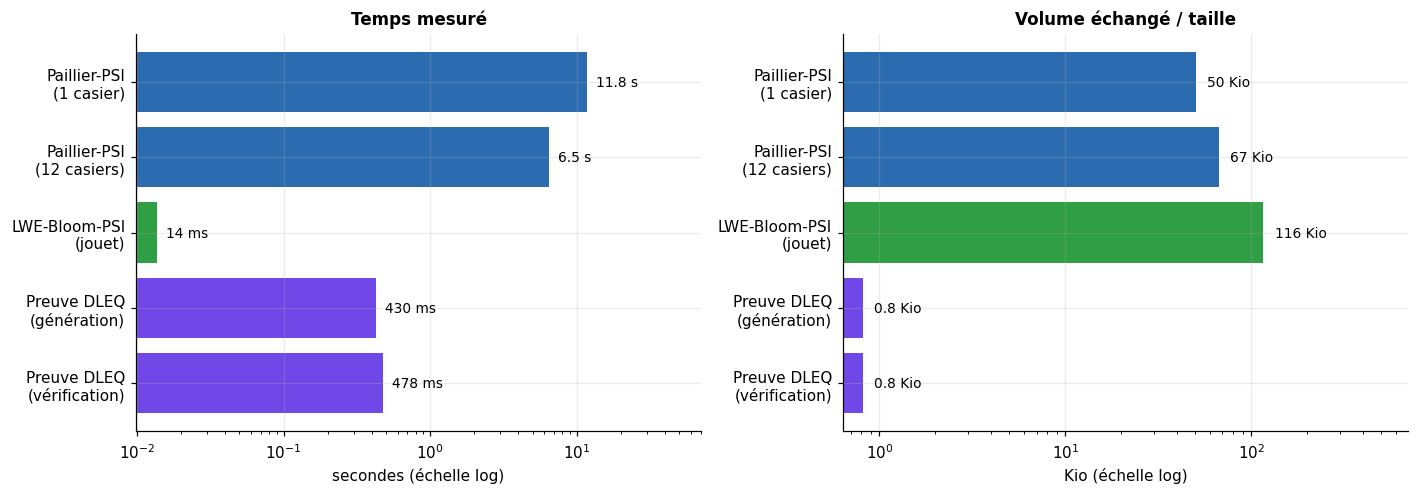

LWE/Bloom-PSI : ×473 plus rapide que Paillier (12 casiers), mais avec faux positifs possibles et fuite des comptes partiels (graphe 3).
Preuve DLEQ batchée : 0.8 Kio pour 100 éléments, vérifiée en 0.48 s.
24 vérifications automatiques réussies ; 5 figures enregistrées dans figures/.


In [23]:
cost = pd.DataFrame([
    {"étape": "Paillier-PSI\n(1 casier)",              "s": r1["time"], "Kio": r1["bytes"] / 1024, "col": C["bleu"]},
    {"étape": f"Paillier-PSI\n({BINS} casiers)",         "s": r2["time"], "Kio": r2["bytes"] / 1024, "col": C["bleu"]},
    {"étape": "LWE-Bloom-PSI\n(jouet)",                 "s": rl["time"], "Kio": rl["bytes"] / 1024, "col": C["vert"]},
    {"étape": "Preuve DLEQ\n(génération)",              "s": tp,         "Kio": proof_kib,          "col": C["violet"]},
    {"étape": "Preuve DLEQ\n(vérification)",            "s": tv,         "Kio": proof_kib,          "col": C["violet"]},
])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, (col, ttl, unit) in zip(axes, (("s", "Temps mesuré", "secondes"), ("Kio", "Volume échangé / taille", "Kio"))):
    bars = ax.barh(cost["étape"], cost[col], color=cost["col"])
    ax.set_xscale("log"); ax.invert_yaxis()
    ax.set_xlim(right=cost[col].max() * 6)
    ax.set_xlabel(f"{unit} (échelle log)"); ax.set_title(ttl)
    for yy, v in enumerate(cost[col]):
        ax.text(v * 1.15, yy, fmt_t(v) if col == "s" else f"{v:.0f} Kio" if v >= 10 else f"{v:.1f} Kio", va="center", fontsize=9)
save_fig(fig, "fig05_synthese_couts")

print(f"LWE/Bloom-PSI : ×{r2['time'] / max(rl['time'], 1e-9):.0f} plus rapide que Paillier ({BINS} casiers), "
      f"mais avec faux positifs possibles et fuite des comptes partiels (graphe 3).")
print(f"Preuve DLEQ batchée : {proof_kib:.1f} Kio pour {len(A_msgs)} éléments, vérifiée en {tv:.2f} s.")
print(f"{len(CHECKS)} vérifications automatiques réussies ; {len(os.listdir(FIG_DIR))} figures enregistrées dans {FIG_DIR}/.")

### Comparaison des deux constructions de PSI
| | PSI polynomial de Paillier | PSI LWE / Bloom (ce notebook) | PSI à base de réseaux en production (FHE, p. ex. APSI) |
|---|---|---|---|
| Hypothèse de difficulté | Résiduosité composite | **LWE** | **(R)LWE** |
| Résistant au quantique | ❌ (Shor) | ✅ | ✅ |
| Tours | 2 | 3 | 2 |
| Calcul | $O(m\cdot L)$ exponentiations modulaires (avec binning) | $O(m\cdot k\cdot n)$ additions — peu coûteux | batching/SIMD |
| Communication | $O(n+m)$ chiffrés | $O(n)$ + $O(m\cdot \text{dim-lwe})$ | $O(n)$ compact |
| Fuite supplémentaire | aucune (au-delà de ∩ et des tailles) | comptes partiels de Bloom + FP | aucune |
| Résultat exact | ✅ (FP du haché 40 bits ≈ 1e-9) | ❌ (FP de Bloom) | ✅ |
| Adapté à | apprendre le HE ; petits ensembles | étude de préparation post-quantique | post-quantique + grands ensembles |

### Enseignements pour le rapport
* **Le simple hachage n'est pas de la confidentialité** (section 2) : les IOC, même réels, ont une faible entropie et sont énumérables. Le PSI offre la fuite *exacte* de la fonctionnalité idéale : l'intersection et les tailles d'ensembles.
* **Le PSI à base de HE** (section 3, Paillier) montre comment l'évaluation homomorphe d'un polynôme cache l'ensemble du serveur ; le **binning** ramène le coût serveur de $O(md)$ à $O(mL)$. Il retrouve exactement le recouvrement réel des deux flux.
* **Le PSI à base de réseaux** (section 4) supprime la faiblesse quantique des constructions à base de factorisation/log discret ; notre version jouet met en évidence les compromis d'ingénierie (faux positifs de Bloom, fuite des comptes partiels, expansion des chiffrés). Les systèmes de production utilisent du FHE RLWE avec empaquetage.
* **Sécurité face à un adversaire malveillant :** une preuve ZK de cohérence de clé (section 5) arrête un serveur qui utilise des clés incohérentes, avec une preuve de taille constante ; mais **aucune cryptographie n'empêche le bourrage d'entrées / l'énumération** (un participant qui soumet tout un /16 comme ensemble apprend lesquelles de ces IP la victime détient) → à combiner avec une politique (plafonds de taille d'ensemble, budgets de sondage, entrées signées, mode cardinalité seule pour les partenaires peu fiables).
* **Interopérabilité** (section 6) : les intersections sont exportées sous forme d'indicateurs STIX 2.1 valides et dédupliqués, qui consignent quel protocole cryptographique les a confirmés ; la cryptographie s'intègre ainsi directement aux outils SOC existants.

### Pistes d'extension du projet
1. Implémenter un vrai schéma **RLWE** (BFV avec SEAL / TenSEAL / OpenFHE) pour un PSI exact et empaqueté, et le brancher dans le même pipeline à la place du filtre de Bloom.
2. Utiliser des **courbes elliptiques** (p. ex. Ristretto255 via `cryptography`/`pynacl`) à la place du groupe MODP 2048 bits : messages et preuves ~10× plus petits.
3. Ajouter une couche **ZK post-quantique** (preuves à base de réseaux ou de hachage) pour que la section 5 résiste aussi au quantique.
4. Encapsuler les protocoles et l'export STIX dans un petit **service HTTP de type TAXII 2.1** avec TLS mutuel et entrées signées.

### Références
* Meadows (1986) *A more efficient cryptographic matchmaking protocol* ; Huberman–Franklin–Hogg (1999) — PSI à aveuglement commutatif (transcription DH de la section 5).
* Paillier (1999) *Public-key cryptosystems based on composite degree residuosity classes* ; Freedman–Nissim–Pinkas (2004) *Efficient private matching and set intersection* — PSI polynomial/HE.
* Regev (2005) *On lattices, learning with errors…* ; NIST FIPS 203 (ML-KEM), FIPS 204 (ML-DSA).
* Chen–Laine–Rindal (2017) *Fast private set intersection from homomorphic encryption* ; Microsoft APSI.
* Chaum–Pedersen (1992) — preuves DLEQ ; Fiat–Shamir (1986).
* RFC 3526 (groupes MODP) ; STIX 2.1 / TAXII 2.1 (OASIS).